Skipping field HORA: unsupported OGR type: 10


Bairros carregados ................... 121
Acidentes carregados ................. 130823
Acidentes fora de qualquer bairro .... 686
Bairros com 0 acidentes .............. 0


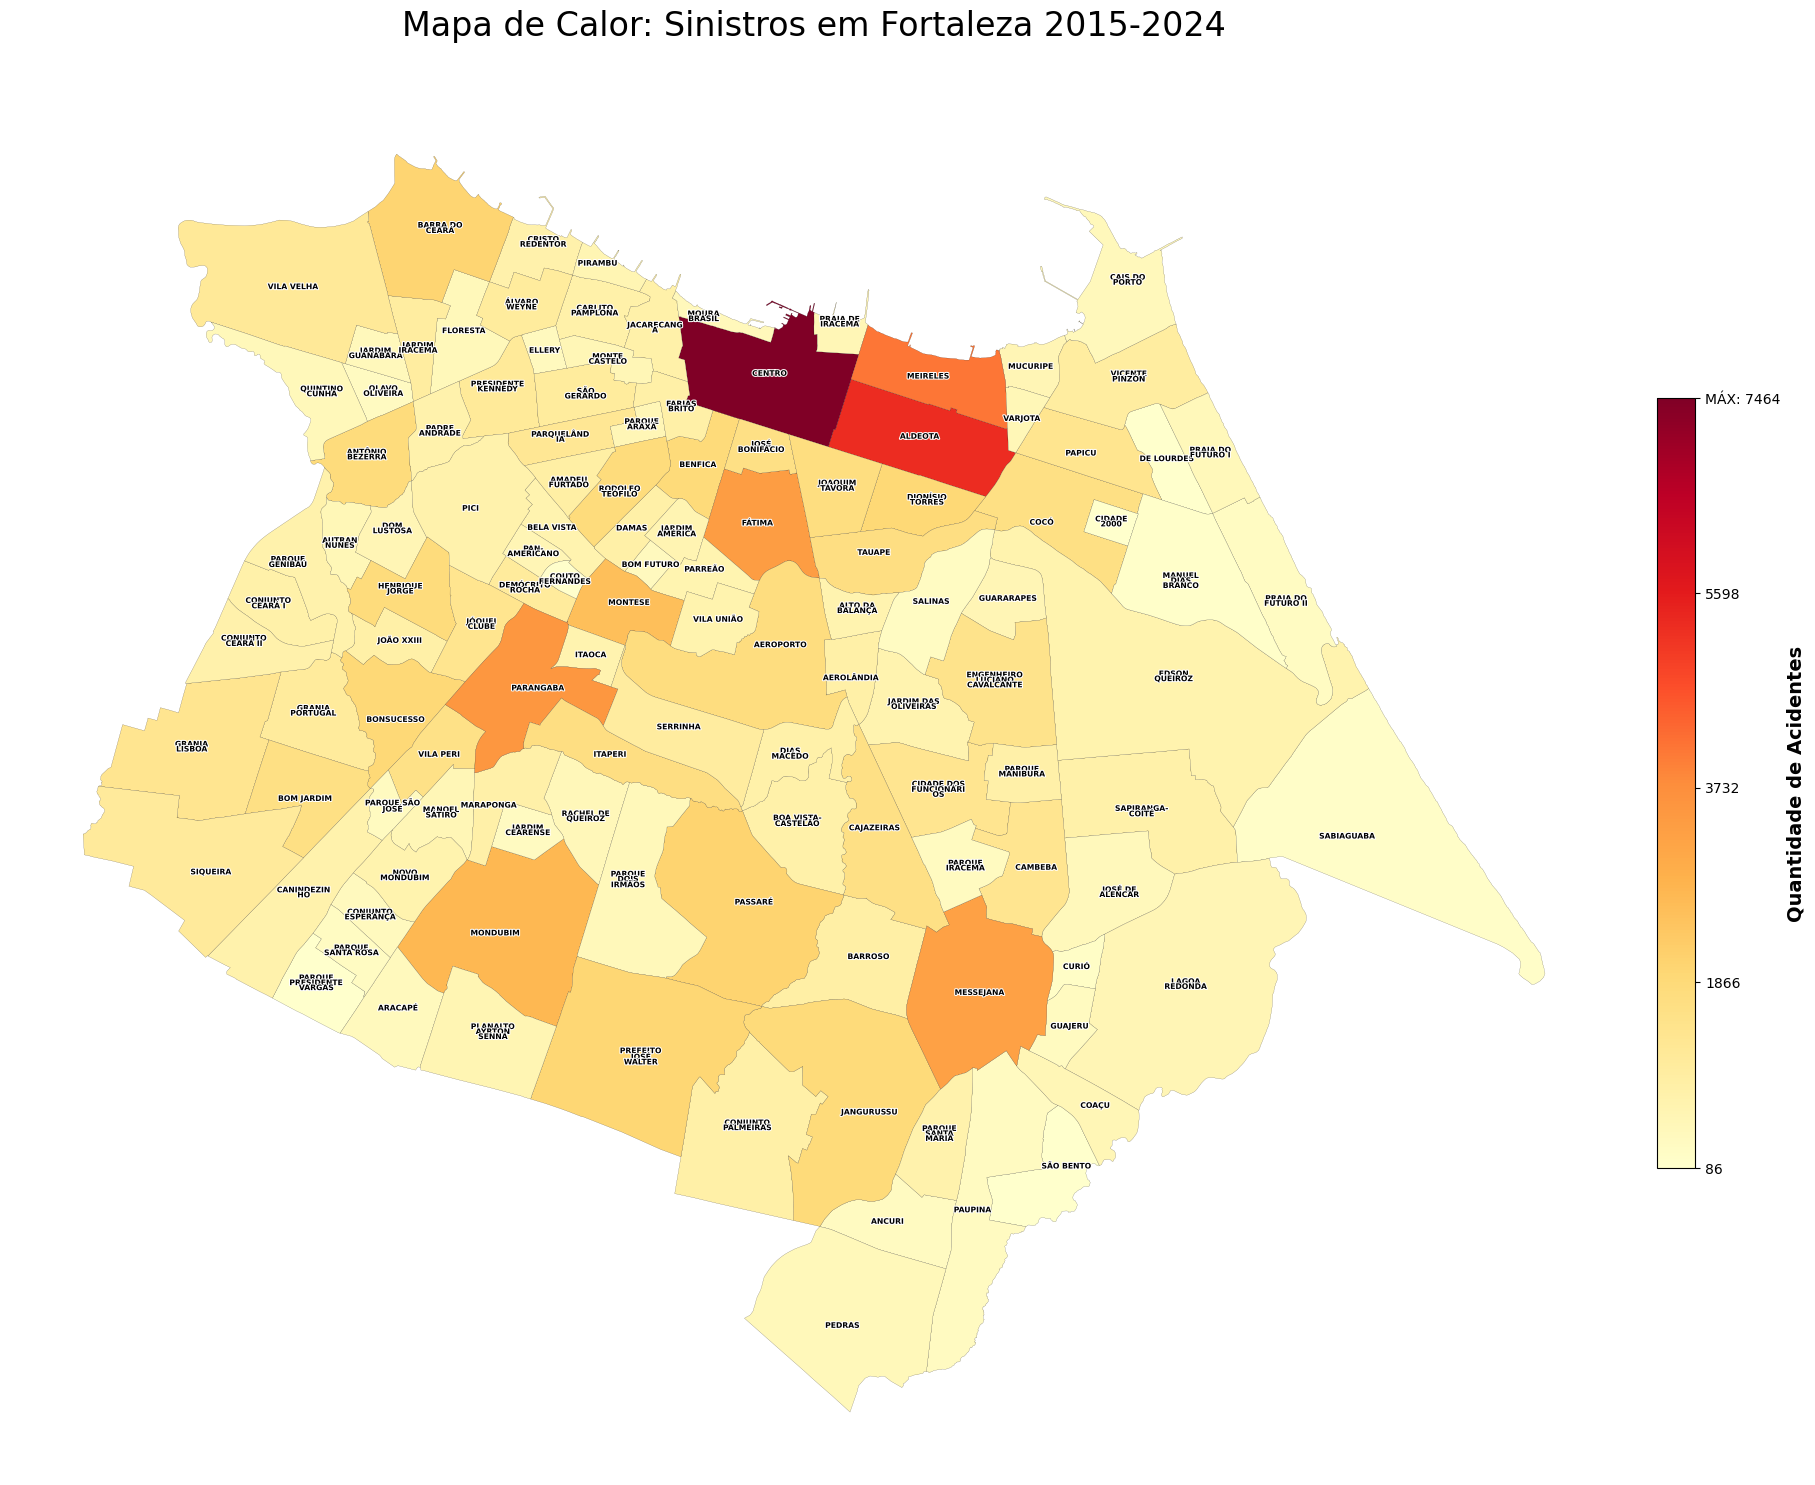

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
import textwrap
from shapely.geometry import Polygon
import xml.etree.ElementTree as ET

# ================================================================
# CAMINHOS DOS ARQUIVOS
# ================================================================
CAMINHO_KML = r'C:\Users\Pichau\Desktop\artigo\bairros.kml'
CAMINHO_GEOJSON = r'C:\Users\Pichau\Desktop\artigo\sinistros-2015-2024.geojson'


def carregar_bairros_kml(caminho):
    tree = ET.parse(caminho)
    root = tree.getroot()
    ns = {'kml': 'http://www.opengis.net/kml/2.2'}

    data = []
    for placemark in root.findall('.//kml:Placemark', ns):
        props = {}
        schema_data = placemark.find('.//kml:SimpleData[@name="nome"]', ns)
        props['nome'] = schema_data.text if schema_data is not None else "N/A"

        coords_tag = placemark.find('.//kml:coordinates', ns)
        if coords_tag is not None:
            pts = [tuple(map(float, p.split(',')[:2])) for p in coords_tag.text.strip().split()]
            if len(pts) >= 3:
                props['geometry'] = Polygon(pts)
                data.append(props)

    return gpd.GeoDataFrame(data, crs='EPSG:4326')


# ---------------------------------------------------------------
# 1) Bairros (carregado UMA vez)
# ---------------------------------------------------------------
bairros_gdf = carregar_bairros_kml(CAMINHO_KML)
bairros_gdf['nome'] = bairros_gdf['nome'].str.strip().str.upper()

# ---------------------------------------------------------------
# 2) Acidentes
# ---------------------------------------------------------------
acidentes_gdf = gpd.read_file(CAMINHO_GEOJSON)
acidentes_gdf = acidentes_gdf.dropna(subset=['geometry'])

if acidentes_gdf.crs is None:
    acidentes_gdf = acidentes_gdf.set_crs("EPSG:4326")
elif acidentes_gdf.crs != "EPSG:4326":
    acidentes_gdf = acidentes_gdf.to_crs("EPSG:4326")

# ---------------------------------------------------------------
# 3) Join espacial + contagem por bairro
# ---------------------------------------------------------------
acidentes_com_bairro = gpd.sjoin(acidentes_gdf, bairros_gdf, how='left', predicate='within')

fora_de_bairro = acidentes_com_bairro['nome'].isna().sum()
contagem = acidentes_com_bairro.groupby('nome').size().reset_index(name='total_acidentes')

mapa_final = bairros_gdf.merge(contagem, on='nome', how='left')
mapa_final['total_acidentes'] = mapa_final['total_acidentes'].fillna(0).astype(int)

# ---- diagnóstico: o que não deu match ----
sem_acidentes = mapa_final.loc[mapa_final['total_acidentes'] == 0, 'nome'].tolist()
print(f"Bairros carregados ................... {len(bairros_gdf)}")
print(f"Acidentes carregados ................. {len(acidentes_gdf)}")
print(f"Acidentes fora de qualquer bairro .... {fora_de_bairro}")
print(f"Bairros com 0 acidentes .............. {len(sem_acidentes)}")
if sem_acidentes:
    print("  -> confira se é zero real ou nome grafado diferente:")
    print("    ", sem_acidentes)

# ---------------------------------------------------------------
# 4) Mapa
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 1, figsize=(25, 20))

vmin = mapa_final['total_acidentes'].min()
vmax = mapa_final['total_acidentes'].max()

mapa_final.plot(column='total_acidentes',
                cmap='YlOrRd',
                ax=ax,
                edgecolor='black',
                linewidth=0.1,
                vmin=vmin,
                vmax=vmax)

sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02)
cbar.set_label('Quantidade de Acidentes', fontsize=14, fontweight='bold')
cbar.set_ticks([vmin, vmax / 4, vmax / 2, 3 * vmax / 4, vmax])
cbar.set_ticklabels([f'{int(vmin)}',
                     f'{int(vmax / 4)}',
                     f'{int(vmax / 2)}',
                     f'{int(3 * vmax / 4)}',
                     f'MÁX: {int(vmax)}'])

for _, row in mapa_final.iterrows():
    centro = row['geometry'].representative_point()
    nome_quebrado = "\n".join(textwrap.wrap(row['nome'], width=10))

    txt = ax.annotate(text=nome_quebrado,
                      xy=(centro.x, centro.y),
                      horizontalalignment='center',
                      verticalalignment='center',
                      fontsize=5.5,
                      fontweight='bold',
                      color='black',
                      linespacing=0.8)
    txt.set_path_effects([patheffects.withStroke(linewidth=1.5, foreground="white")])

ax.set_title('Mapa de Calor: Sinistros em Fortaleza 2015-2024', fontsize=24, pad=40)
ax.axis('off')

plt.show()

In [2]:
# 1. Ordenar os dados (do maior para o menor)
ranking = contagem.sort_values(by='total_acidentes', ascending=False)

# 2. Pegar os 5 primeiros (Mais acidentes)
top_5_mais = ranking.head(5)

# 3. Pegar os 5 últimos (Menos acidentes - removendo quem tem zero se preferir)
# Se quiser considerar apenas bairros que tiveram PELO MENOS 1 acidente:
top_5_menos = ranking[ranking['total_acidentes'] > 0].tail(5).sort_values(by='total_acidentes')

print("-" * 30)
print("5 BAIRROS COM MAIS ACIDENTES")
print("-" * 30)
print(top_5_mais.to_string(index=False))

print("\n" + "-" * 30)
print("5 BAIRROS COM MENOS ACIDENTES")
print("-" * 30)
print(top_5_menos.to_string(index=False))


------------------------------
5 BAIRROS COM MAIS ACIDENTES
------------------------------
     nome  total_acidentes
   CENTRO             7464
  ALDEOTA             5284
 MEIRELES             4098
PARANGABA             3524
   FÁTIMA             3378

------------------------------
5 BAIRROS COM MENOS ACIDENTES
------------------------------
                    nome  total_acidentes
              DE LOURDES               86
             CIDADE 2000               89
               SÃO BENTO              105
PARQUE PRESIDENTE VARGAS              114
         COUTO FERNANDES              131


In [3]:
import geopandas as gpd

# 1. Carregar o arquivo
arquivo = "sinistros-2015-2024.geojson"
gdf = gpd.read_file(arquivo)

# 2. Mapeamento para padronização (Dicionário: {valor_antigo: valor_novo})
mapeamento_cruzamento = {
    "Meio de Quadra": "Meio de quadra",
    "Meio De Quadra": "Meio de quadra",
    "Com Via Férrea": "Com via férrea"
}

# Aplicar a substituição na coluna TIPOCRUZAMENTO
gdf["TIPOCRUZAMENTO"] = gdf["TIPOCRUZAMENTO"].replace(mapeamento_cruzamento)

# 3. Escolha as colunas que quer analisar
colunas = ["NATUREZA", "SEVERIDADE", "TIPOCRUZAMENTO", "USOSOLO"]

# 4. Loop para imprimir os resultados
for col in colunas:
    print(f"\n--- CONTAGEM PARA: {col} ---")
    print(gdf[col].value_counts())
    print(f"Total de categorias únicas: {gdf[col].nunique()}")

Skipping field HORA: unsupported OGR type: 10



--- CONTAGEM PARA: NATUREZA ---
NATUREZA
Colisão                                  58544
Queda                                    15444
Colisão Transversal                      14078
Colisão Lateral                          12942
Atropelamento                            11180
Colisão Traseira                          9368
Choque c/ Obstáculo Fixo                  2812
Colisão Frontal                           1342
Não informado                             1254
Engavetamento                             1180
Queda de moto                              749
Outros                                     554
Capotamento                                550
Choque                                     281
Tombamento                                 221
Atropelamento de Animal                    146
Colisão Lateral Sentido Oposto              85
Acidente Pessoal                            60
ACIDENTE ONIBUS (TRANSPORTE COLETIVO)       32
Acidente com transporte ferroviário          1
Name: count, dtype

In [4]:
import pandas as pd
import json

# 1. Carregar o arquivo GeoJSON usando a biblioteca nativa 'json'
arquivo = "sinistros-2015-2024.geojson"

with open(arquivo, 'r', encoding='utf-8') as f:
    dados_json = json.load(f)

# 2. Transformar apenas a parte das 'properties' (os dados) em um DataFrame do Pandas
# Isso ignora as coordenadas geográficas para focar na análise de horários
df = pd.DataFrame([feature['properties'] for feature in dados_json['features']])

# 3. Limpeza da coluna HORA (remove espaços e garante que seja texto)
df['HORA'] = df['HORA'].astype(str).str.strip()

# 4. Converter para tempo e pegar a hora. 
# O format='%H:%M:%S' funciona para "20:10:00", mas o pandas é inteligente para outros formatos também
df['HORA_LIMPA'] = pd.to_datetime(df['HORA'], errors='coerce').dt.hour

# 5. Remover linhas onde o horário estava vazio ou inválido
df = df.dropna(subset=['HORA_LIMPA'])

# 6. Definir as faixas (bins) e as etiquetas (labels)
faixas = [0, 6, 12, 18, 24]
labels = ['Madrugada', 'Manhã', 'Tarde', 'Noite']

# 7. Criar a coluna de período
df['PERIODO'] = pd.cut(df['HORA_LIMPA'], bins=faixas, labels=labels, right=False)

# --- RESULTADOS ---
print("--- DISTRIBUIÇÃO DOS ACIDENTES POR PERÍODO ---")
contagem = df['PERIODO'].value_counts()
print(contagem)

print("\n--- PORCENTAGEM (%) ---")
print((df['PERIODO'].value_counts(normalize=True) * 100).round(2))

C:\Users\Pichau\AppData\Local\Temp\ipykernel_17764\3517118828.py:19: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['HORA_LIMPA'] = pd.to_datetime(df['HORA'], errors='coerce').dt.hour


--- DISTRIBUIÇÃO DOS ACIDENTES POR PERÍODO ---
PERIODO
Tarde        45401
Manhã        41864
Noite        24973
Madrugada    18585
Name: count, dtype: int64

--- PORCENTAGEM (%) ---
PERIODO
Tarde        34.70
Manhã        32.00
Noite        19.09
Madrugada    14.21
Name: proportion, dtype: float64


In [5]:
import pandas as pd
import json

# 1. Carregar o arquivo
arquivo = "sinistros-2015-2024.geojson"
with open(arquivo, 'r', encoding='utf-8') as f:
    dados_json = json.load(f)

# 2. Criar o DataFrame
df = pd.DataFrame([feature['properties'] for feature in dados_json['features']])

# 3. Padronização e Limpeza
# Remove espaços, vírgulas no fim e garante que tudo seja string para comparar
for col in ['LOG1', 'LOG2']:
    df[col] = df[col].astype(str).str.strip().str.rstrip(',')

# 4. Definir o que deve ser ignorado
valores_para_ignorar = ['', 'nan', 'none', 'não informado', 'nao informado']

# --- ANÁLISE 1: Top 5 LOG1 ---
# Filtramos LOG1 para não pegar nomes inválidos
df_log1_limpo = df[~df['LOG1'].str.lower().isin(valores_para_ignorar)]
print("TOP 5 LOGS COM MAIS ACIDENTES (LOG1):")
print(df_log1_limpo['LOG1'].value_counts().head(5))

print("\n" + "="*45 + "\n")

# --- ANÁLISE 2: Top 5 Combinações (LOG1 + LOG2) ---
# Aqui aplicamos o filtro no LOG2 conforme solicitado
df_comb_limpo = df[
    (~df['LOG1'].str.lower().isin(valores_para_ignorar)) & 
    (~df['LOG2'].str.lower().isin(valores_para_ignorar))
].copy()

print("TOP 5 COMBINAÇÕES (LOG1 e LOG2):")
top_combinacoes = df_comb_limpo.groupby(['LOG1', 'LOG2']).size().sort_values(ascending=False).head(5)
print(top_combinacoes)

TOP 5 LOGS COM MAIS ACIDENTES (LOG1):
LOG1
RD CE-040                                    2035
AVENIDA SEN CARLOS JEREISSATI (AEROPORTO)     704
AVENIDA SANTOS DUMONT                         541
AVENIDA ANTONIO SALES                         493
AVENIDA DOMINGOS OLIMPIO                      490
Name: count, dtype: int64


TOP 5 COMBINAÇÕES (LOG1 e LOG2):
LOG1                      LOG2                     
AVENIDA ABOLICAO          AVENIDA DES MOREIRA          58
AVENIDA DOMINGOS OLIMPIO  RUA FLORIANO PEIXOTO         53
AVENIDA ANTONIO SALES     RUA NUNES VALENTE            51
AVENIDA GOV RAUL BARBOSA  AVENIDA GAL MURILO BORGES    45
AVENIDA OLIVEIRA PAIVA    AVENIDA DES GONZAGA          43
dtype: int64


In [6]:
"""
Proporção de acidentes por bairro em relação à população - Fortaleza, 2014-2022
Roda o mesmo cálculo para todos os anos disponíveis.

Fontes por ano:
 - bairros.geojson                              : polígonos oficiais dos bairros (fixo, não muda por ano)
 - acidentes_por_ano/sinistros-{ano}.geojson     : pontos dos acidentes de trânsito do ano
 - população fortaleza por ano/{ano-1}-{ano}.xls : população por bairro (HTML disfarçado de .xls)
   ex.: sinistros-2015.geojson  <->  2014-2015.xls
"""

import glob
import json
import os
import re
import unicodedata

import geopandas as gpd
import pandas as pd
from bs4 import BeautifulSoup

# ================================================================
# >>> COLOQUE AQUI OS CAMINHOS DAS SUAS PASTAS/ARQUIVOS <<<
# ================================================================
CAMINHO_BAIRROS = r"C:\Users\Pichau\Desktop\artigo\bairros.geojson"
PASTA_ACIDENTES = r"C:\Users\Pichau\Desktop\artigo\acidentes_por_ano"
PASTA_POPULACAO = r"C:\Users\Pichau\Desktop\artigo\população fortaleza bairros por ano"

ANOS = range(2014, 2023)  # 2014 até 2022 (inclusive)
# ================================================================

# Nomes que aparecem escritos de forma diferente entre bairros.geojson e as
# tabelas de população. Se novos anos tiverem outras divergências, é só
# acrescentar aqui.
ALIAS = {
    "CONJUNTO PALMEIRAS": "PALMEIRAS",
    "DE LOURDES": "LOURDES",
    "SAPIRANGA-COITE": "SAPIRANGA COITE",
    "BONSUCESSO": "BOM SUCESSO",
    "ELLERY": "VILA ELLERY",
    "SAO GERARDO": "SAO GERARDO/ALAGADICO",
    "TAUAPE": "SAO JOAO DO TAUAPE",
    "MEIRELES": "PRAIA DO MEIRELES",
    "BOA VISTA-CASTELAO": "BOA VISTA",
    "GUAJERU": "GUAJIRU",
    "MANOEL SATIRO": "VILA MANOEL SATIRO",
    "ENGENHEIRO LUCIANO CAVALCANTE": "LUCIANO CAVALCANTE",
    "PAN-AMERICANO": "PAN AMERICANO",
    "PLANALTO AYRTON SENNA": "PLANALTO AIRTON SENNA",
}


def normaliza(nome: str) -> str:
    """Remove acentos, espaços extras e deixa em maiúsculas para permitir o join dos nomes."""
    nome = nome.strip().upper()
    nome = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"\s+", " ", nome)
    return nome


# ---------------------------------------------------------------
# Bairros (polígonos) - carregado uma única vez, é o mesmo para todos os anos
# ---------------------------------------------------------------
def carrega_bairros(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        bairros_raw = json.load(f)

    # o arquivo tem duas camadas misturadas:
    #  - features com o campo "bairro" -> são PONTOS (rótulo/centróide de cada bairro)
    #  - features com o campo "nome"   -> são os POLÍGONOS reais do limite do bairro
    feats_poligonos = [
        ft for ft in bairros_raw["features"]
        if "bairro" not in ft["properties"] and ft["geometry"]["type"] in ("Polygon", "MultiPolygon")
    ]
    gdf = gpd.GeoDataFrame.from_features(feats_poligonos, crs="EPSG:4326")
    gdf = gdf.rename(columns={"nome": "bairro"})
    gdf["bairro_norm"] = gdf["bairro"].apply(normaliza)
    gdf["bairro_norm"] = gdf["bairro_norm"].replace(ALIAS)
    return gdf[["bairro", "bairro_norm", "geometry"]]


# ---------------------------------------------------------------
# População (HTML disfarçado de .xls) - um arquivo por ano
# ---------------------------------------------------------------
def carrega_populacao(caminho: str) -> pd.DataFrame:
    with open(caminho, encoding="ISO-8859-1") as f:
        html = f.read()

    soup = BeautifulSoup(html, "html.parser")
    linhas = soup.find("table").find("tbody").find_all("tr")

    pop_rows = []
    for tr in linhas:
        tds = [td.get_text(strip=True) for td in tr.find_all("td")]
        if tds:
            # 1ª coluna = nome do bairro, última coluna = população total
            # (o nº de faixas etárias no meio pode variar de ano pra ano)
            nome = tds[0]
            total = tds[-1].replace(".", "").strip()
            pop_rows.append((nome, total))

    pop_df = pd.DataFrame(pop_rows, columns=["bairro", "populacao"])
    pop_df = pop_df[pop_df["bairro"].str.upper() != "TOTAL"].copy()
    pop_df["populacao"] = pd.to_numeric(pop_df["populacao"], errors="coerce").astype("Int64")
    pop_df["bairro_norm"] = pop_df["bairro"].apply(normaliza).replace(ALIAS)
    return pop_df[["bairro_norm", "populacao"]]


# ---------------------------------------------------------------
# Acidentes (pontos) - um arquivo por ano
# ---------------------------------------------------------------
def carrega_acidentes(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        sinistros_raw = json.load(f)
    return gpd.GeoDataFrame.from_features(sinistros_raw["features"], crs="EPSG:4326")


# ---------------------------------------------------------------
# Calcula a proporção de um único ano
# ---------------------------------------------------------------
def calcula_ano(ano: int, bairros_gdf: gpd.GeoDataFrame):
    caminho_sin = os.path.join(PASTA_ACIDENTES, f"sinistros-{ano}.geojson")
    caminho_pop = os.path.join(PASTA_POPULACAO, f"{ano - 1}-{ano}.xls")

    if not os.path.exists(caminho_sin):
        print(f"[{ano}] arquivo de acidentes não encontrado: {caminho_sin}")
        return None
    if not os.path.exists(caminho_pop):
        print(f"[{ano}] arquivo de população não encontrado: {caminho_pop}")
        return None

    sin_gdf = carrega_acidentes(caminho_sin)
    pop_df = carrega_populacao(caminho_pop)

    sin_com_bairro = gpd.sjoin(sin_gdf, bairros_gdf, how="left", predicate="within")
    acidentes_por_bairro = (
        sin_com_bairro.groupby("bairro_norm").size().reset_index(name="n_acidentes")
    )
    sem_bairro = sin_com_bairro["bairro_norm"].isna().sum()

    base_bairros = bairros_gdf[["bairro", "bairro_norm"]].drop_duplicates()
    df = base_bairros.merge(pop_df, on="bairro_norm", how="left")
    df = df.merge(acidentes_por_bairro, on="bairro_norm", how="left")
    df["n_acidentes"] = df["n_acidentes"].fillna(0).astype(int)

    df["acidentes_por_habitante"] = df["n_acidentes"] / df["populacao"]
    df["acidentes_por_mil_hab"] = df["acidentes_por_habitante"] * 1_000
    df = df.sort_values("acidentes_por_mil_hab", ascending=False)

    total_acidentes_georref = int(df["n_acidentes"].sum())
    total_acidentes_bruto = len(sin_gdf)
    total_populacao = int(pop_df["populacao"].sum())
    media_geral_por_habitante = total_acidentes_georref / total_populacao
    media_geral_por_mil_hab = media_geral_por_habitante * 1_000

    resumo = {
        "ano": ano,
        "total_acidentes_bruto": total_acidentes_bruto,
        "total_acidentes_georref": total_acidentes_georref,
        "acidentes_fora_de_bairro": int(sem_bairro),
        "populacao_total": total_populacao,
        "media_por_habitante": media_geral_por_habitante,
        "media_por_mil_hab": media_geral_por_mil_hab,
    }
    return df, resumo


# ---------------------------------------------------------------
# Roda para todos os anos
# ---------------------------------------------------------------
bairros_gdf = carrega_bairros(CAMINHO_BAIRROS)

resumos = []
tabelas_por_ano = {}

for ano in ANOS:
    resultado = calcula_ano(ano, bairros_gdf)
    if resultado is None:
        continue
    df_ano, resumo = resultado
    tabelas_por_ano[ano] = df_ano
    resumos.append(resumo)

    print("=" * 70)
    print(f"RESUMO {ano}")
    print("=" * 70)
    print(f"Total de acidentes no arquivo original ......... {resumo['total_acidentes_bruto']}")
    print(f"Acidentes localizados dentro de algum bairro .... {resumo['total_acidentes_georref']}")
    print(f"Acidentes fora dos polígonos de bairro .......... {resumo['acidentes_fora_de_bairro']}")
    print(f"População total (soma dos bairros) .............. {resumo['populacao_total']}")
    print(f"Média geral de acidentes por habitante ........... {resumo['media_por_habitante']:.6f}")
    print(f"Média geral de acidentes por 1.000 habitantes .... {resumo['media_por_mil_hab']:.2f}")
    print()
    print(f"TABELA COMPLETA {ano} - todos os bairros (ordenado por proporção)")
    cols = ["bairro", "n_acidentes", "populacao", "acidentes_por_mil_hab"]
    print(df_ano[cols].to_string(index=False))
    print()

# ---------------------------------------------------------------
# Evolução da média geral da cidade ao longo dos anos
# ---------------------------------------------------------------
if resumos:
    evolucao = pd.DataFrame(resumos)[
        ["ano", "total_acidentes_georref", "populacao_total", "media_por_mil_hab"]
    ]
    print("=" * 70)
    print("EVOLUÇÃO DA MÉDIA GERAL DA CIDADE POR ANO")
    print("=" * 70)
    print(evolucao.to_string(index=False))

[2014] arquivo de acidentes não encontrado: C:\Users\Pichau\Desktop\artigo\acidentes_por_ano\sinistros-2014.geojson
RESUMO 2015
Total de acidentes no arquivo original ......... 16831
Acidentes localizados dentro de algum bairro .... 16790
Acidentes fora dos polígonos de bairro .......... 41
População total (soma dos bairros) .............. 2571899
Média geral de acidentes por habitante ........... 0.006528
Média geral de acidentes por 1.000 habitantes .... 6.53

TABELA COMPLETA 2015 - todos os bairros (ordenado por proporção)
                       bairro  n_acidentes  populacao  acidentes_por_mil_hab
                       CENTRO         1177      29932              39.322464
               JOSÉ BONIFÁCIO          297       9279              32.007759
                    AEROPORTO          237       9039              26.219715
             PRAIA DE IRACEMA           85       3283              25.890953
                       FÁTIMA          584      24447              23.888412
      

C:\Users\Pichau\AppData\Local\Temp\ipykernel_17764\2134918599.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


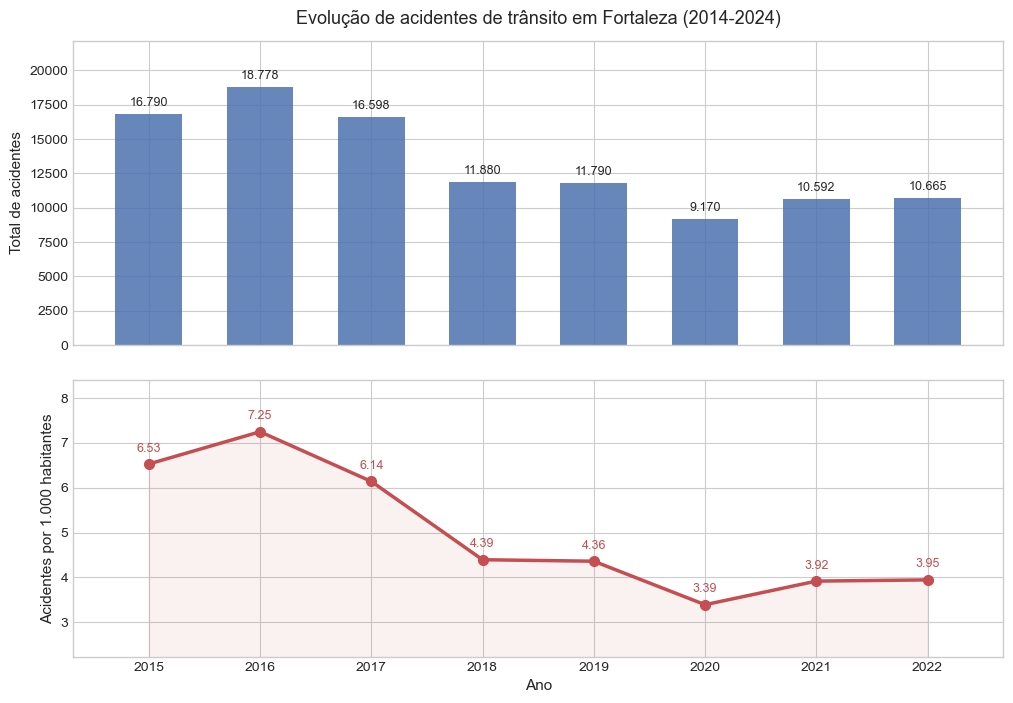

In [7]:
"""
Gráfico resumido da evolução de acidentes de trânsito em Fortaleza.

Este arquivo é independente do script de cálculo (acidentes_bairro_multi_ano.py),
mas usa o resultado real dele.

Como usar:

  A) Dentro do MESMO notebook onde já rodou o acidentes_bairro_multi_ano.py
     (ou seja, a variável `evolucao` já existe na memória):
         cole a função `plotar_evolucao` abaixo numa célula e chame:
             plotar_evolucao(evolucao)

  B) Rodando este arquivo separado (python grafico_evolucao.py):
         o bloco no final importa `evolucao` diretamente de
         acidentes_bairro_multi_ano.py — ou seja, ele executa o pipeline
         completo (leitura dos geojson/xls, join espacial, cálculo por ano)
         e só então desenha o gráfico com os números reais.
         Os dois arquivos precisam estar na mesma pasta.

Colunas esperadas no DataFrame `evolucao`:
    ano                     -> int, ex.: 2022
    total_acidentes_georref -> int, total de acidentes daquele ano
    media_por_mil_hab       -> float, acidentes a cada 1.000 habitantes (pode ser NaN)
"""

import pandas as pd
import matplotlib.pyplot as plt


def plotar_evolucao(evolucao: pd.DataFrame, salvar_como: str | None = "evolucao_acidentes_fortaleza.png"):
    """Desenha o gráfico resumido da evolução dos acidentes, em dois painéis empilhados:
       - painel de cima: total de acidentes por ano (barras)
       - painel de baixo: proporção de acidentes por 1.000 habitantes (linha)

    Parâmetros
    ----------
    evolucao : pd.DataFrame
        Precisa ter as colunas: ano, total_acidentes_georref, media_por_mil_hab.
    salvar_como : str ou None
        Caminho/nome do arquivo .png a salvar. Passe None para não salvar em disco.
    """
    evolucao = evolucao.sort_values("ano")

    cor_barra = "#4C72B0"
    cor_linha = "#C44E52"

    plt.style.use("seaborn-v0_8-whitegrid")
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True,
        gridspec_kw={"height_ratios": [1.1, 1], "hspace": 0.12},
    )

    # ---- painel de cima: total de acidentes -----------------------------
    ax1.bar(
        evolucao["ano"],
        evolucao["total_acidentes_georref"],
        color=cor_barra,
        alpha=0.85,
        width=0.6,
        zorder=2,
    )
    ax1.set_ylabel("Total de acidentes", fontsize=11)
    ax1.set_ylim(0, evolucao["total_acidentes_georref"].max() * 1.18)
    ax1.set_title("Evolução de acidentes de trânsito em Fortaleza (2014-2024)", fontsize=13, pad=12)

    for ano, valor in zip(evolucao["ano"], evolucao["total_acidentes_georref"]):
        ax1.text(ano, valor + evolucao["total_acidentes_georref"].max() * 0.02,
                  f"{int(valor):,}".replace(",", "."), ha="center", va="bottom", fontsize=9)

    # ---- painel de baixo: proporção por 1.000 hab ------------------------
    validos = evolucao.dropna(subset=["media_por_mil_hab"])
    ax2.plot(
        validos["ano"],
        validos["media_por_mil_hab"],
        color=cor_linha,
        marker="o",
        markersize=7,
        linewidth=2.5,
        zorder=3,
    )
    ax2.fill_between(validos["ano"], validos["media_por_mil_hab"], color=cor_linha, alpha=0.08)

    for ano, valor in zip(validos["ano"], validos["media_por_mil_hab"]):
        ax2.annotate(f"{valor:.2f}", (ano, valor), textcoords="offset points",
                     xytext=(0, 9), ha="center", fontsize=9, color=cor_linha)

    ax2.set_ylabel("Acidentes por 1.000 habitantes", fontsize=11)
    ax2.set_xlabel("Ano", fontsize=11)
    ax2.set_xticks(evolucao["ano"])
    margem = (validos["media_por_mil_hab"].max() - validos["media_por_mil_hab"].min()) * 0.3 or 0.3
    ax2.set_ylim(validos["media_por_mil_hab"].min() - margem, validos["media_por_mil_hab"].max() + margem)

    # sombreia o trecho sem dado de população, pra ficar claro que não é zero
    sem_pop = evolucao[evolucao["media_por_mil_hab"].isna()]
    if not sem_pop.empty:
        inicio = sem_pop["ano"].min() - 0.5
        fim = sem_pop["ano"].max() + 0.5
        ax2.axvspan(inicio, fim, color="grey", alpha=0.12)
        ax2.text((inicio + fim) / 2, ax2.get_ylim()[0] + margem * 0.15,
                 "sem dado\nde população", ha="center", va="bottom",
                 fontsize=8.5, color="#666666", style="italic")

    fig.tight_layout()

    if salvar_como:
        plt.savefig(salvar_como, dpi=150, bbox_inches="tight")

    plt.show()


if __name__ == "__main__":
    # ------------------------------------------------------------
    # Se você está num notebook (Jupyter) e já rodou o script principal
    # numa célula anterior, a variável `evolucao` já existe em memória.
    # Nesse caso, NÃO precisa deste bloco — é só colar a função
    # `plotar_evolucao` numa célula e chamar:
    #
    #     plotar_evolucao(evolucao)
    #
    # O bloco abaixo só serve para quando você roda ESTE arquivo como
    # um script de terminal separado (python grafico_evolucao.py), e
    # nesse caso precisa que acidentes_bairro_multi_ano.py exista como
    # arquivo .py de verdade, salvo na mesma pasta.
    # ------------------------------------------------------------


    plotar_evolucao(evolucao)

In [8]:
"""
Impacto da instalação de semáforos nos acidentes de trânsito - Fortaleza

Ideia: para cada semáforo com data de implantação conhecida, desenha um
quadrado ao redor dele (na prática, uma área de influência quadrada) e conta
quantos acidentes aconteceram DENTRO desse quadrado ANTES e DEPOIS da
instalação, numa janela de tempo simétrica (ex.: 2 anos antes / 2 anos depois).

Fontes:
 - dadosabertos_semaforosctafor.geojson : semáforos, com data de implantação
 - sinistros-2015-2024.geojson          : acidentes de 2015 a 2024 (dia/mês/ano + lat/long)
"""

import json
from datetime import datetime, timedelta

import geopandas as gpd
import pandas as pd
from shapely.geometry import box, shape

# ================================================================
# >>> COLOQUE AQUI OS CAMINHOS DOS SEUS ARQUIVOS <<<
# ================================================================
CAMINHO_SEMAFOROS = r"C:\Users\Pichau\Desktop\artigo\dadosabertos_semaforosctafor.geojson"
CAMINHO_SINISTROS = r"C:\Users\Pichau\Desktop\artigo\sinistros-2015-2024.geojson"
CAMINHO_SAIDA_GEOJSON = r"C:\Users\Pichau\Desktop\artigo\acidentes_em_semáforos.geojson"

# ================================================================
# >>> PARÂMETROS DA ANÁLISE <<<
# ================================================================
JANELA_ANOS = 2          # quantos anos antes/depois da instalação comparar
LADO_QUADRADO_M = 150    # tamanho do lado do quadrado ao redor do semáforo (metros)

# intervalo de datas coberto pelos dados de acidentes (ajuste se seu arquivo for diferente)
DATA_MIN_DADOS = datetime(2015, 1, 1)
DATA_MAX_DADOS = datetime(2024, 12, 31)

# CRS métrico apropriado para Fortaleza/CE (SIRGAS 2000 / UTM zone 24S)
CRS_METRICO = "EPSG:31984"
CRS_GEOGRAFICO = "EPSG:4674"  # SIRGAS2000, é o CRS declarado nos dois arquivos originais


# ---------------------------------------------------------------
# 1) Carrega semáforos e filtra os que têm janela completa de dados
# ---------------------------------------------------------------
def carrega_semaforos(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    registros = []
    for ft in raw["features"]:
        props = ft["properties"]
        data_str = props.get("DATA_IMPLANTAÇÃO")
        if not data_str:
            continue
        try:
            data_instalacao = datetime.strptime(data_str, "%d/%m/%Y")
        except ValueError:
            continue

        inicio_antes = data_instalacao - timedelta(days=365 * JANELA_ANOS)
        fim_depois = data_instalacao + timedelta(days=365 * JANELA_ANOS)

        # só entra na análise quem tem a janela ANTES e DEPOIS totalmente
        # coberta pelos dados de acidentes que temos
        if inicio_antes < DATA_MIN_DADOS or fim_depois > DATA_MAX_DADOS:
            continue

        registros.append({
            "codigo": props.get("CÓDIGO"),
            "cruzamento": props.get("CRUZAMENTO"),
            "bairro": props.get("BAIRRO"),
            "data_instalacao": data_instalacao,
            "inicio_antes": inicio_antes,
            "fim_depois": fim_depois,
            "geometry": shape(ft["geometry"]),
        })

    if not registros:
        raise ValueError(
            "Nenhum semáforo com janela completa de dados encontrado. "
            "Tente diminuir JANELA_ANOS ou conferir DATA_MIN_DADOS/DATA_MAX_DADOS."
        )

    gdf = gpd.GeoDataFrame(registros, geometry="geometry", crs=CRS_GEOGRAFICO)
    return gdf.to_crs(CRS_METRICO)


def classifica_periodo_dia(hora) -> str:
    """Classifica o horário do acidente em madrugada/manhã/tarde/noite, a partir do campo HORA (ex.: '16:13:00')."""
    if not hora or not isinstance(hora, str):
        return "não informado"
    try:
        h = int(hora.split(":")[0])
    except (ValueError, IndexError):
        return "não informado"

    if 0 <= h < 6:
        return "madrugada (0h-6h)"
    elif 6 <= h < 12:
        return "manhã (6h-12h)"
    elif 12 <= h < 18:
        return "tarde (12h-18h)"
    elif 18 <= h < 24:
        return "noite (18h-24h)"
    return "não informado"


# ---------------------------------------------------------------
# 2) Carrega acidentes com data real (dia/mês/ano) e projeta pro CRS métrico
# ---------------------------------------------------------------
def carrega_acidentes(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["data"] = pd.to_datetime(
        dict(year=gdf["ANO"], month=gdf["MES"], day=gdf["DIA"]), errors="coerce"
    )
    gdf = gdf.dropna(subset=["data"])
    gdf["periodo_dia"] = gdf["HORA"].apply(classifica_periodo_dia)
    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 3) Monta o quadrado de influência ao redor de cada semáforo
# ---------------------------------------------------------------
def monta_quadrados(semaforos_gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    meia_lado = LADO_QUADRADO_M / 2
    quadrados = semaforos_gdf.copy()
    quadrados["geometry"] = quadrados.geometry.apply(
        lambda p: box(p.x - meia_lado, p.y - meia_lado, p.x + meia_lado, p.y + meia_lado)
    )
    return quadrados


# ---------------------------------------------------------------
# 4) Conta acidentes ANTES e DEPOIS para cada semáforo
#    (e guarda os acidentes individuais marcados, pra exportar depois)
# ---------------------------------------------------------------
def periodo_pico(subset: pd.DataFrame) -> str:
    """Retorna o período do dia (madrugada/manhã/tarde/noite) com mais acidentes nesse subconjunto."""
    if subset.empty:
        return "sem acidentes"
    contagem = subset["periodo_dia"].value_counts()
    return contagem.idxmax()


def calcula_antes_depois(semaforos_gdf, quadrados_gdf, acidentes_gdf):
    juncao = gpd.sjoin(acidentes_gdf, quadrados_gdf, how="inner", predicate="within")

    linhas = []
    acidentes_marcados = []

    for idx, sem in semaforos_gdf.iterrows():
        dentro = juncao[juncao["index_right"] == idx]

        antes = dentro[(dentro["data"] >= sem["inicio_antes"]) & (dentro["data"] < sem["data_instalacao"])]
        depois = dentro[(dentro["data"] >= sem["data_instalacao"]) & (dentro["data"] < sem["fim_depois"])]

        n_antes = len(antes)
        n_depois = len(depois)
        mortos_antes = int(antes["MORTOS"].sum())
        mortos_depois = int(depois["MORTOS"].sum())
        feridos_antes = int(antes["FERIDOS"].sum())
        feridos_depois = int(depois["FERIDOS"].sum())

        if n_antes > 0:
            variacao_pct = (n_depois - n_antes) / n_antes * 100
        else:
            variacao_pct = float("nan")

        pico_antes = periodo_pico(antes)
        pico_depois = periodo_pico(depois)
        # só marca como "mudou" se os dois períodos tiverem acidentes de fato
        # (senão "sem acidentes" vira um falso positivo de mudança)
        mudou_pico = (
            pico_antes != pico_depois
            and pico_antes != "sem acidentes"
            and pico_depois != "sem acidentes"
        )

        linhas.append({
            "codigo": sem["codigo"],
            "cruzamento": sem["cruzamento"],
            "bairro": sem["bairro"],
            "data_instalacao": sem["data_instalacao"].date(),
            "acidentes_antes": n_antes,
            "acidentes_depois": n_depois,
            "diferenca_absoluta": n_depois - n_antes,
            "variacao_pct": variacao_pct,
            "mortos_antes": mortos_antes,
            "mortos_depois": mortos_depois,
            "feridos_antes": feridos_antes,
            "feridos_depois": feridos_depois,
            "periodo_pico_antes": pico_antes,
            "periodo_pico_depois": pico_depois,
            "mudou_periodo_pico": mudou_pico,
        })

        for periodo, subset in (("antes", antes), ("depois", depois)):
            if subset.empty:
                continue
            marcado = subset.drop(columns=[
                "index_right", "codigo", "cruzamento", "bairro",
                "data_instalacao", "inicio_antes", "fim_depois",
            ]).copy()
            marcado["semaforo_codigo"] = sem["codigo"]
            marcado["semaforo_cruzamento"] = sem["cruzamento"]
            marcado["semaforo_bairro"] = sem["bairro"]
            marcado["semaforo_data_instalacao"] = sem["data_instalacao"].date().isoformat()
            marcado["periodo"] = periodo
            acidentes_marcados.append(marcado)

    resultado_df = pd.DataFrame(linhas)

    if acidentes_marcados:
        acidentes_marcados_gdf = gpd.GeoDataFrame(
            pd.concat(acidentes_marcados, ignore_index=True), geometry="geometry", crs=acidentes_gdf.crs
        )
    else:
        acidentes_marcados_gdf = gpd.GeoDataFrame(columns=list(acidentes_gdf.columns) + [
            "semaforo_codigo", "semaforo_cruzamento", "semaforo_data_instalacao", "periodo"
        ], geometry="geometry", crs=acidentes_gdf.crs)

    return resultado_df, acidentes_marcados_gdf


# ---------------------------------------------------------------
# Execução
# ---------------------------------------------------------------
semaforos_gdf = carrega_semaforos(CAMINHO_SEMAFOROS)
acidentes_gdf = carrega_acidentes(CAMINHO_SINISTROS)
quadrados_gdf = monta_quadrados(semaforos_gdf)

resultado, acidentes_marcados_gdf = calcula_antes_depois(semaforos_gdf, quadrados_gdf, acidentes_gdf)
resultado = resultado.sort_values("variacao_pct")

# ---------------------------------------------------------------
# Salva acidentes + quadrados JUNTOS num único GeoJSON, pra visualizar
# no QGIS/Kepler/etc. Uma coluna 'tipo_feature' diferencia o que é
# ponto (acidente) do que é polígono (quadrado do semáforo).
# ---------------------------------------------------------------
acidentes_para_salvar = acidentes_marcados_gdf.to_crs(CRS_GEOGRAFICO).copy()
acidentes_para_salvar["tipo_feature"] = "acidente"

quadrados_para_salvar = quadrados_gdf.drop(columns=["inicio_antes", "fim_depois"]).to_crs(CRS_GEOGRAFICO).copy()
quadrados_para_salvar["data_instalacao"] = quadrados_para_salvar["data_instalacao"].astype(str)
quadrados_para_salvar["tipo_feature"] = "quadrado"
quadrados_para_salvar = quadrados_para_salvar.rename(columns={
    "codigo": "semaforo_codigo",
    "cruzamento": "semaforo_cruzamento",
    "bairro": "semaforo_bairro",
    "data_instalacao": "semaforo_data_instalacao",
})
# anexa as métricas calculadas (variação %, período de pico antes/depois etc.)
# direto no quadrado, pra aparecer ao clicar no polígono no QGIS/etc.
metricas = resultado.set_index("codigo")[[
    "acidentes_antes", "acidentes_depois", "diferenca_absoluta", "variacao_pct",
    "periodo_pico_antes", "periodo_pico_depois", "mudou_periodo_pico",
]]
quadrados_para_salvar = quadrados_para_salvar.merge(
    metricas, left_on="semaforo_codigo", right_index=True, how="left"
)

combinado = gpd.GeoDataFrame(
    pd.concat([acidentes_para_salvar, quadrados_para_salvar], ignore_index=True),
    crs=CRS_GEOGRAFICO,
)
combinado.to_file(CAMINHO_SAIDA_GEOJSON, driver="GeoJSON")

print(f"\nGeoJSON combinado salvo em: {CAMINHO_SAIDA_GEOJSON}")
print(f"  {len(acidentes_para_salvar)} acidentes (geometria Point) + "
      f"{len(quadrados_para_salvar)} quadrados (geometria Polygon)")
print("Use a coluna 'tipo_feature' ('acidente'/'quadrado') pra filtrar/simbolizar cada um "
      "separadamente no seu programa de visualização, e 'periodo' ('antes'/'depois') "
      "pra colorir os acidentes.")

# ---------------------------------------------------------------
# Resumo geral
# ---------------------------------------------------------------
com_variacao = resultado.dropna(subset=["variacao_pct"])
total_antes = int(resultado["acidentes_antes"].sum())
total_depois = int(resultado["acidentes_depois"].sum())
variacao_total_pct = (total_depois - total_antes) / total_antes * 100 if total_antes > 0 else float("nan")

melhor = com_variacao.iloc[0]     # maior queda (variação mais negativa)
pior = com_variacao.iloc[-1]      # menor queda / maior aumento

n_reduziram = (com_variacao["variacao_pct"] < 0).sum()
n_aumentaram = (com_variacao["variacao_pct"] > 0).sum()
n_iguais = (com_variacao["variacao_pct"] == 0).sum()

print("=" * 78)
print(f"IMPACTO DE SEMÁFOROS NOS ACIDENTES — JANELA DE {JANELA_ANOS} ANOS ANTES/DEPOIS")
print(f"Quadrado de influência: {LADO_QUADRADO_M} m de lado")
print("=" * 78)
print(f"Semáforos analisados (com janela completa de dados) ... {len(resultado)}")
print(f"Total de acidentes ANTES da instalação ................. {total_antes}")
print(f"Total de acidentes DEPOIS da instalação ................. {total_depois}")
print(f"Variação percentual geral ............................... {variacao_total_pct:.1f}%")
print(f"Média simples da variação % entre os semáforos .......... {com_variacao['variacao_pct'].mean():.1f}%")
print(f"Mediana da variação % .................................... {com_variacao['variacao_pct'].median():.1f}%")
print(f"Semáforos onde o nº de acidentes CAIU ................... {n_reduziram}")
print(f"Semáforos onde o nº de acidentes AUMENTOU ............... {n_aumentaram}")
print(f"Semáforos sem mudança ..................................... {n_iguais}")
print(f"Total de mortos ANTES / DEPOIS ........................... {int(resultado['mortos_antes'].sum())} / {int(resultado['mortos_depois'].sum())}")
print(f"Total de feridos ANTES / DEPOIS ........................... {int(resultado['feridos_antes'].sum())} / {int(resultado['feridos_depois'].sum())}")

print()
print("-" * 78)
print("LOGRADOURO/CRUZAMENTO ONDE MAIS DIMINUIU (maior queda %)")
print("-" * 78)
print(f"{melhor['cruzamento']} ({melhor['bairro']})")
print(f"  Instalado em: {melhor['data_instalacao']}")
print(f"  Antes: {melhor['acidentes_antes']} acidentes  |  Depois: {melhor['acidentes_depois']} acidentes")
print(f"  Variação: {melhor['variacao_pct']:.1f}%")

print()
print("-" * 78)
print("LOGRADOURO/CRUZAMENTO ONDE MENOS DIMINUIU (ou mais aumentou)")
print("-" * 78)
print(f"{pior['cruzamento']} ({pior['bairro']})")
print(f"  Instalado em: {pior['data_instalacao']}")
print(f"  Antes: {pior['acidentes_antes']} acidentes  |  Depois: {pior['acidentes_depois']} acidentes")
print(f"  Variação: {pior['variacao_pct']:.1f}%")

print()
print("=" * 78)
print("TABELA COMPLETA (ordenada da maior queda para o maior aumento)")
print("=" * 78)
cols = ["cruzamento", "bairro", "data_instalacao", "acidentes_antes", "acidentes_depois",
        "diferenca_absoluta", "variacao_pct", "periodo_pico_antes", "periodo_pico_depois",
        "mudou_periodo_pico"]
print(resultado[cols].to_string(index=False))

print()
print("-" * 78)
print("SEMÁFOROS SEM NENHUM ACIDENTE 'ANTES' (variação % não calculável)")
print("-" * 78)
sem_variacao = resultado[resultado["variacao_pct"].isna()]
print(sem_variacao[["cruzamento", "bairro", "acidentes_antes", "acidentes_depois"]].to_string(index=False))

print()
print("=" * 78)
print(f"SEMÁFOROS ONDE O PERÍODO DE PICO DE ACIDENTES MUDOU ({int(resultado['mudou_periodo_pico'].sum())} de {len(resultado)})")
print("=" * 78)
mudaram = resultado[resultado["mudou_periodo_pico"]]
if mudaram.empty:
    print("Nenhum semáforo mudou o período de pico.")
else:
    cols_pico = ["cruzamento", "bairro", "acidentes_antes", "acidentes_depois",
                 "periodo_pico_antes", "periodo_pico_depois"]
    print(mudaram[cols_pico].to_string(index=False))

print()
print("=" * 78)
print("DISTRIBUIÇÃO POR PERÍODO DO DIA (todos os semáforos somados)")
print("=" * 78)
ordem_periodos = ["madrugada (0h-6h)", "manhã (6h-12h)", "tarde (12h-18h)", "noite (18h-24h)", "não informado"]
por_periodo = (
    acidentes_marcados_gdf.groupby(["periodo_dia", "periodo"]).size()
    .unstack(fill_value=0)
    .reindex(ordem_periodos)
    .fillna(0)
    .astype(int)
)
if "antes" not in por_periodo.columns:
    por_periodo["antes"] = 0
if "depois" not in por_periodo.columns:
    por_periodo["depois"] = 0
por_periodo = por_periodo[["antes", "depois"]]
por_periodo["diferenca"] = por_periodo["depois"] - por_periodo["antes"]
por_periodo["variacao_pct"] = por_periodo.apply(
    lambda r: (r["diferenca"] / r["antes"] * 100) if r["antes"] > 0 else float("nan"), axis=1
)
print(por_periodo.to_string())


GeoJSON combinado salvo em: C:\Users\Pichau\Desktop\artigo\acidentes_em_semáforos.geojson
  4582 acidentes (geometria Point) + 282 quadrados (geometria Polygon)
Use a coluna 'tipo_feature' ('acidente'/'quadrado') pra filtrar/simbolizar cada um separadamente no seu programa de visualização, e 'periodo' ('antes'/'depois') pra colorir os acidentes.
IMPACTO DE SEMÁFOROS NOS ACIDENTES — JANELA DE 2 ANOS ANTES/DEPOIS
Quadrado de influência: 150 m de lado
Semáforos analisados (com janela completa de dados) ... 282
Total de acidentes ANTES da instalação ................. 2795
Total de acidentes DEPOIS da instalação ................. 1787
Variação percentual geral ............................... -36.1%
Média simples da variação % entre os semáforos .......... -3.5%
Mediana da variação % .................................... -33.3%
Semáforos onde o nº de acidentes CAIU ................... 178
Semáforos onde o nº de acidentes AUMENTOU ............... 78
Semáforos sem mudança .....................

In [9]:
CAMINHO_SEMAFOROS = r"C:\Users\Pichau\Desktop\artigo\dadosabertos_semaforosctafor.geojson"
CAMINHO_SINISTROS = r"C:\Users\Pichau\Desktop\artigo\sinistros-2015-2024.geojson"
CAMINHO_SAIDA_GEOJSON = r"C:\Users\Pichau\Desktop\artigo\acidentes_em_semáforos.geojson"

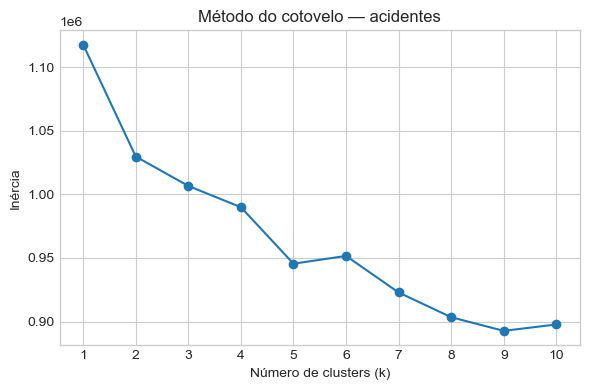

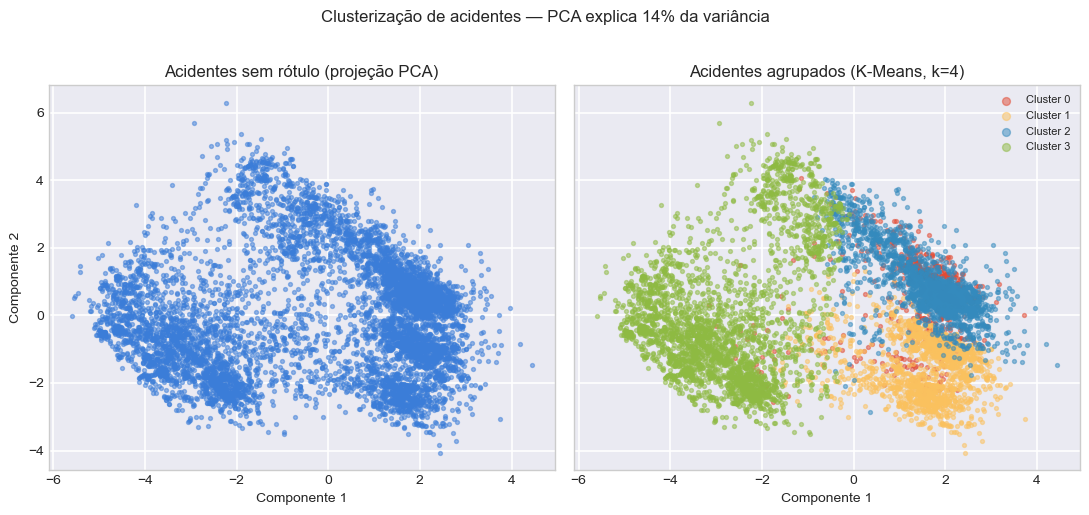

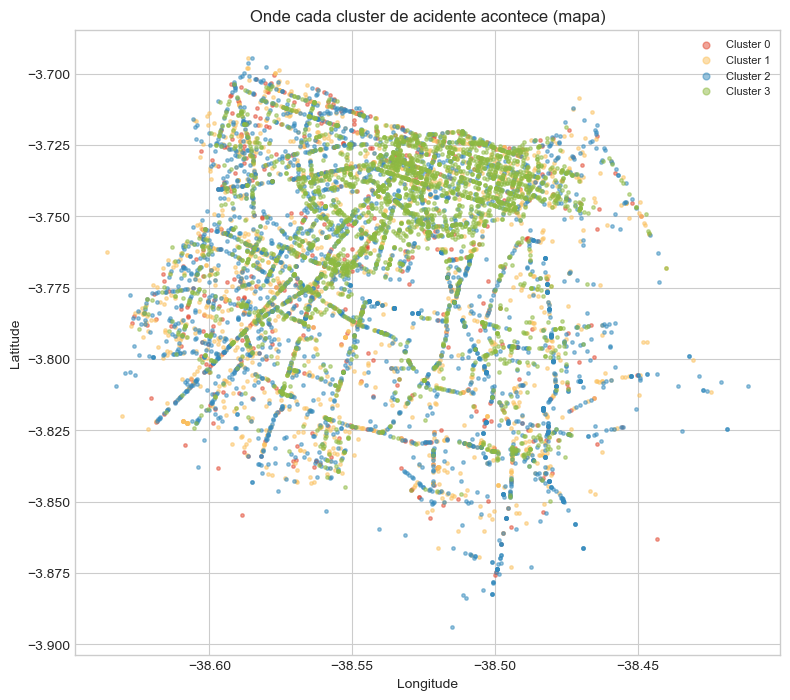

PERFIL DE CADA CLUSTER (k=4)
Tamanho de cada cluster:
cluster
0    10542
1    29631
2    42677
3    47973
Name: count, dtype: int64

------------------------------------------------------------------------------
CLUSTER 0  (10542 acidentes, 8.1% do total)
------------------------------------------------------------------------------
Médias numéricas:
MORTOS               0.11
FERIDOS              1.18
ILESOS               0.18
AUTOMOVEL            0.39
MOTOCICLETA          0.42
BICICLETA            0.02
CAMINHAO             0.02
dist_semaforo_m    255.06

Categoria mais comum em cada campo:
  NATUREZA: ATROPELAMENTO (96% do cluster)
  periodo_dia: tarde (38% do cluster)
  dia_semana: Saturday (17% do cluster)
  CONTROLETRAFEGO: NÃO INFORMADO (88% do cluster)
  TIPOCRUZAMENTO: MEIO DE QUADRA (79% do cluster)
  modo_controle_proximo: LOCAL (35% do cluster)

------------------------------------------------------------------------------
CLUSTER 1  (29631 acidentes, 22.6% do total)
--------

In [10]:
"""
Clusterização dos acidentes de trânsito - Fortaleza

Agrupa os acidentes (K-Means) usando variáveis combinadas de dois arquivos:

  - sinistros-2015-2024.geojson: severidade (mortos/feridos/ilesos), tipos de
    veículo envolvidos, natureza do acidente, tipo de cruzamento, controle de
    tráfego no local, horário/dia da semana/mês.

  - dadosabertos_semaforosctafor.geojson: usado pra calcular a distância de
    cada acidente até o semáforo mais próximo, e trazer características
    desse semáforo (modo de controle, se tem botão de pedestre, etc.)

A ideia é ver se emergem "perfis" de acidente (ex.: acidentes noturnos de
moto com alta gravidade longe de semáforo x colisões leves de carro de dia
perto de semáforo centralizado etc.) — tanto num gráfico 2D (via PCA) quanto
num mapa (lat/long) colorido por cluster.
"""

import json
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ================================================================
# >>> PARÂMETROS <<<
# ================================================================
K_CLUSTERS = 4                  # número de grupos (ajuste depois de olhar o cotovelo)
K_MAX_TESTAR = 10               # até quantos clusters testar no método do cotovelo
DISTANCIA_MAX_SEMAFORO_M = 300  # além disso, considera "sem semáforo próximo"
AMOSTRA_PARA_GRAFICO = 8000     # nº de pontos plotados (só pra não poluir o gráfico)
RANDOM_STATE = 42

CRS_METRICO = "EPSG:31984"      # SIRGAS 2000 / UTM 24S (Fortaleza/CE)
CRS_GEOGRAFICO = "EPSG:4674"


# ---------------------------------------------------------------
# Funções auxiliares
# ---------------------------------------------------------------
def classifica_periodo_dia(hora) -> str:
    if not hora or not isinstance(hora, str):
        return "não informado"
    try:
        h = int(hora.split(":")[0])
    except (ValueError, IndexError):
        return "não informado"
    if 0 <= h < 6:
        return "madrugada"
    elif 6 <= h < 12:
        return "manhã"
    elif 12 <= h < 18:
        return "tarde"
    elif 18 <= h < 24:
        return "noite"
    return "não informado"


def normaliza_texto(serie: pd.Series) -> pd.Series:
    return serie.fillna("não informado").astype(str).str.strip().str.upper()


def agrupa_raras(serie: pd.Series, top_n: int) -> pd.Series:
    """Mantém só as top_n categorias mais frequentes; o resto vira 'OUTROS'."""
    mais_frequentes = serie.value_counts().head(top_n).index
    return serie.where(serie.isin(mais_frequentes), "OUTROS")


# ---------------------------------------------------------------
# 1) Carrega acidentes + engenharia de atributos de tempo
# ---------------------------------------------------------------
def carrega_acidentes(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["data"] = pd.to_datetime(
        dict(year=gdf["ANO"], month=gdf["MES"], day=gdf["DIA"]), errors="coerce"
    )
    gdf = gdf.dropna(subset=["data"]).reset_index(drop=True)

    gdf["periodo_dia"] = gdf["HORA"].apply(classifica_periodo_dia)
    gdf["dia_semana"] = gdf["data"].dt.day_name()
    gdf["mes"] = gdf["data"].dt.month

    for campo in ["NATUREZA", "TIPOCRUZAMENTO", "CONTROLETRAFEGO", "USOSOLO", "SEVERIDADE"]:
        gdf[campo] = normaliza_texto(gdf[campo])

    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 2) Carrega semáforos (todos com coordenada válida)
# ---------------------------------------------------------------
def carrega_semaforos(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)
    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["MODO_CONTROLE"] = normaliza_texto(gdf["MODO_CONTROLE"])
    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 3) Pra cada acidente, acha o semáforo mais próximo (KDTree)
# ---------------------------------------------------------------
def anexa_semaforo_mais_proximo(acidentes_gdf, semaforos_gdf) -> pd.DataFrame:
    coords_acidentes = np.column_stack([acidentes_gdf.geometry.x, acidentes_gdf.geometry.y])
    coords_semaforos = np.column_stack([semaforos_gdf.geometry.x, semaforos_gdf.geometry.y])

    arvore = cKDTree(coords_semaforos)
    distancias, indices = arvore.query(coords_acidentes, k=1)

    modo_controle_proximo = semaforos_gdf["MODO_CONTROLE"].values[indices]
    modo_controle_proximo = np.where(
        distancias <= DISTANCIA_MAX_SEMAFORO_M, modo_controle_proximo, "SEM SEMÁFORO PRÓXIMO"
    )

    resultado = acidentes_gdf.copy()
    resultado["dist_semaforo_m"] = distancias
    resultado["perto_de_semaforo"] = distancias <= DISTANCIA_MAX_SEMAFORO_M
    resultado["modo_controle_proximo"] = modo_controle_proximo
    return resultado


# ---------------------------------------------------------------
# 4) Monta a matriz de atributos (numéricos + categóricos em dummies)
# ---------------------------------------------------------------
def monta_matriz_atributos(df: pd.DataFrame):
    numericos = df[[
        "MORTOS", "FERIDOS", "ILESOS",
        "AUTOMOVEL", "ONIBUS", "BICICLETA", "CAMINHAO", "MICROONIBUS",
        "CICLOMOTOR", "MOTOCICLETA", "TRACAOANIMAL", "TREM",
        "dist_semaforo_m", "mes",
    ]].fillna(0)

    categoricos_config = {
        "NATUREZA": 8,
        "TIPOCRUZAMENTO": 6,
        "CONTROLETRAFEGO": 6,
        "USOSOLO": 3,
        "periodo_dia": 5,
        "dia_semana": 7,
        "modo_controle_proximo": 6,
    }
    blocos_categoricos = []
    for campo, top_n in categoricos_config.items():
        agrupado = agrupa_raras(df[campo], top_n)
        dummies = pd.get_dummies(agrupado, prefix=campo)
        blocos_categoricos.append(dummies)

    matriz = pd.concat([numericos.reset_index(drop=True)] + [b.reset_index(drop=True) for b in blocos_categoricos], axis=1)
    return matriz


# ---------------------------------------------------------------
# Execução
# ---------------------------------------------------------------
acidentes_gdf = carrega_acidentes(CAMINHO_SINISTROS)
semaforos_gdf = carrega_semaforos(CAMINHO_SEMAFOROS)
acidentes_gdf = anexa_semaforo_mais_proximo(acidentes_gdf, semaforos_gdf)

matriz = monta_matriz_atributos(acidentes_gdf)
scaler = StandardScaler()
matriz_padronizada = scaler.fit_transform(matriz)

# ---------------------------------------------------------------
# Método do cotovelo (numa amostra, só pra não demorar demais)
# ---------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
idx_amostra_cotovelo = rng.choice(len(matriz_padronizada), size=min(20000, len(matriz_padronizada)), replace=False)

inercias = []
ks_testados = range(1, K_MAX_TESTAR + 1)
for k in ks_testados:
    modelo = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, batch_size=1024)
    modelo.fit(matriz_padronizada[idx_amostra_cotovelo])
    inercias.append(modelo.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(ks_testados), inercias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — acidentes")
plt.xticks(list(ks_testados))
plt.tight_layout()
plt.savefig("acidentes_metodo_cotovelo.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# K-Means final (nos dados todos)
# ---------------------------------------------------------------
kmeans = MiniBatchKMeans(n_clusters=K_CLUSTERS, random_state=RANDOM_STATE, n_init=10, batch_size=2048)
clusters = kmeans.fit_predict(matriz_padronizada)
acidentes_gdf["cluster"] = clusters

# ---------------------------------------------------------------
# PCA só pra poder visualizar em 2D
# ---------------------------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
componentes = pca.fit_transform(matriz_padronizada)
acidentes_gdf["pca_1"] = componentes[:, 0]
acidentes_gdf["pca_2"] = componentes[:, 1]
variancia_explicada = pca.explained_variance_ratio_.sum() * 100

# amostra só pra deixar o gráfico legível
idx_plot = rng.choice(len(acidentes_gdf), size=min(AMOSTRA_PARA_GRAFICO, len(acidentes_gdf)), replace=False)
amostra = acidentes_gdf.iloc[idx_plot]

CORES = ["#E24A33", "#FBC15E", "#348ABD", "#8EBA42", "#988ED5", "#FFB5B8", "#777777"]

# ---- painel 1: PCA sem rótulo x PCA colorido por cluster ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.set_facecolor("#EAEAF2")
    ax.grid(color="white", linewidth=1.2)
    ax.set_axisbelow(True)

ax1.scatter(amostra["pca_1"], amostra["pca_2"], color="#3B7DD8", s=8, alpha=0.5)
ax1.set_title("Acidentes sem rótulo (projeção PCA)")
ax1.set_xlabel(f"Componente 1")
ax1.set_ylabel(f"Componente 2")

for i in range(K_CLUSTERS):
    grupo = amostra[amostra["cluster"] == i]
    ax2.scatter(grupo["pca_1"], grupo["pca_2"], color=CORES[i % len(CORES)], s=8, alpha=0.5, label=f"Cluster {i}")
ax2.set_title(f"Acidentes agrupados (K-Means, k={K_CLUSTERS})")
ax2.set_xlabel("Componente 1")
ax2.legend(markerscale=2, fontsize=8)

fig.suptitle(f"Clusterização de acidentes — PCA explica {variancia_explicada:.0f}% da variância", y=1.02)
fig.tight_layout()
plt.savefig("acidentes_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- painel 2: mapa (lat/long) colorido por cluster ----
plt.figure(figsize=(8, 8))
for i in range(K_CLUSTERS):
    grupo = amostra[amostra["cluster"] == i]
    plt.scatter(grupo["LONGITUDE"], grupo["LATITUDE"], color=CORES[i % len(CORES)], s=6, alpha=0.5, label=f"Cluster {i}")
plt.title("Onde cada cluster de acidente acontece (mapa)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=2, fontsize=8)
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.savefig("acidentes_clusters_mapa.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Perfil de cada cluster — o que caracteriza cada grupo
# ---------------------------------------------------------------
print("=" * 78)
print(f"PERFIL DE CADA CLUSTER (k={K_CLUSTERS})")
print("=" * 78)
print(f"Tamanho de cada cluster:\n{acidentes_gdf['cluster'].value_counts().sort_index()}\n")

campos_numericos_perfil = ["MORTOS", "FERIDOS", "ILESOS", "AUTOMOVEL", "MOTOCICLETA",
                           "BICICLETA", "CAMINHAO", "dist_semaforo_m"]
campos_categoricos_perfil = ["NATUREZA", "periodo_dia", "dia_semana", "CONTROLETRAFEGO",
                             "TIPOCRUZAMENTO", "modo_controle_proximo"]

for i in range(K_CLUSTERS):
    grupo = acidentes_gdf[acidentes_gdf["cluster"] == i]
    print("-" * 78)
    print(f"CLUSTER {i}  ({len(grupo)} acidentes, {len(grupo)/len(acidentes_gdf)*100:.1f}% do total)")
    print("-" * 78)
    print("Médias numéricas:")
    print(grupo[campos_numericos_perfil].mean().round(2).to_string())
    print("\nCategoria mais comum em cada campo:")
    for campo in campos_categoricos_perfil:
        moda = grupo[campo].mode()
        if not moda.empty:
            pct = (grupo[campo] == moda.iloc[0]).mean() * 100
            print(f"  {campo}: {moda.iloc[0]} ({pct:.0f}% do cluster)")
    print()

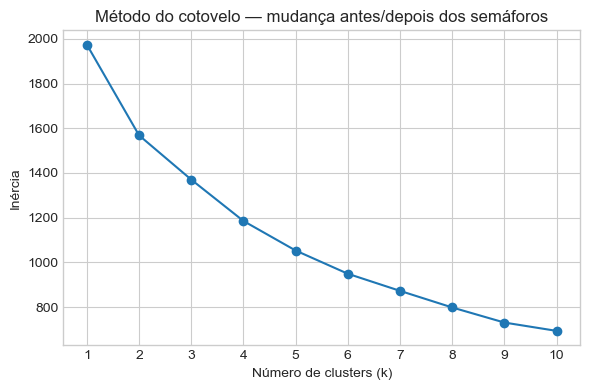

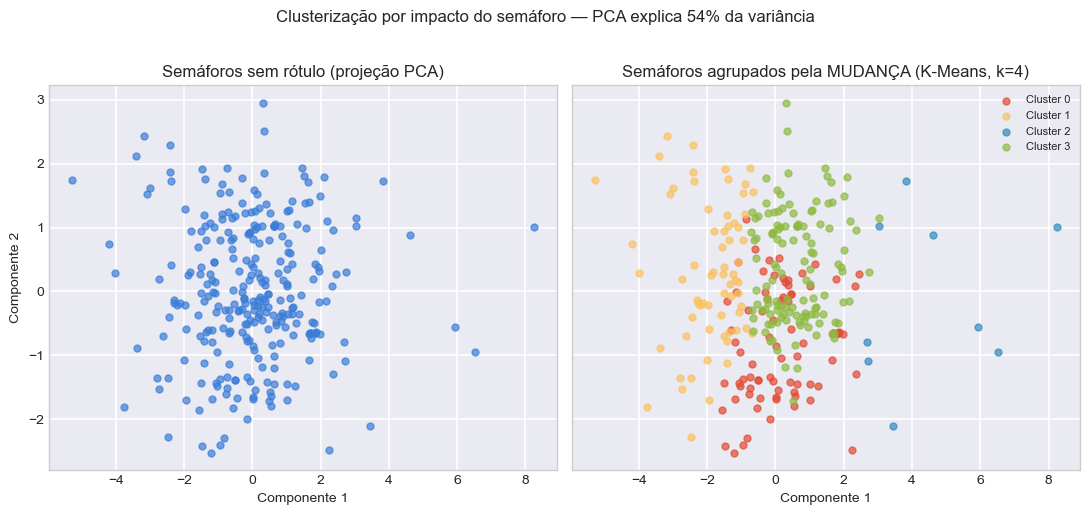

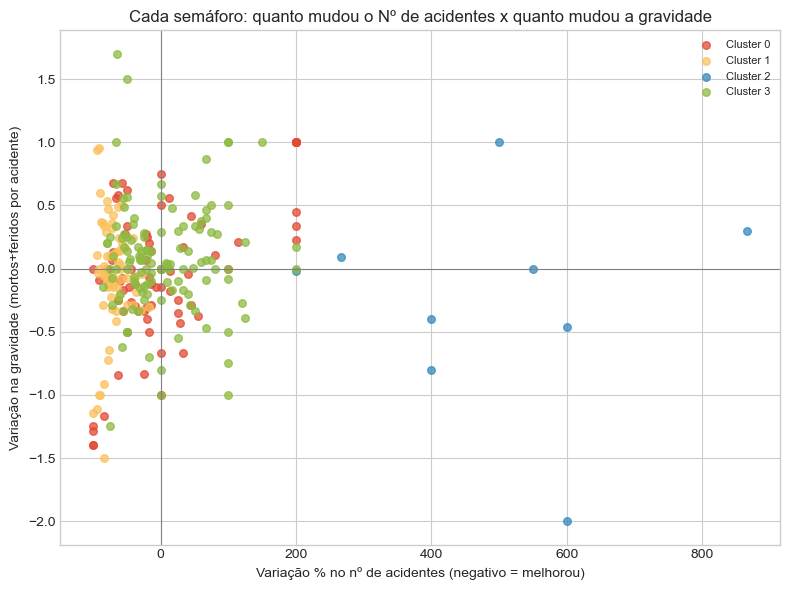

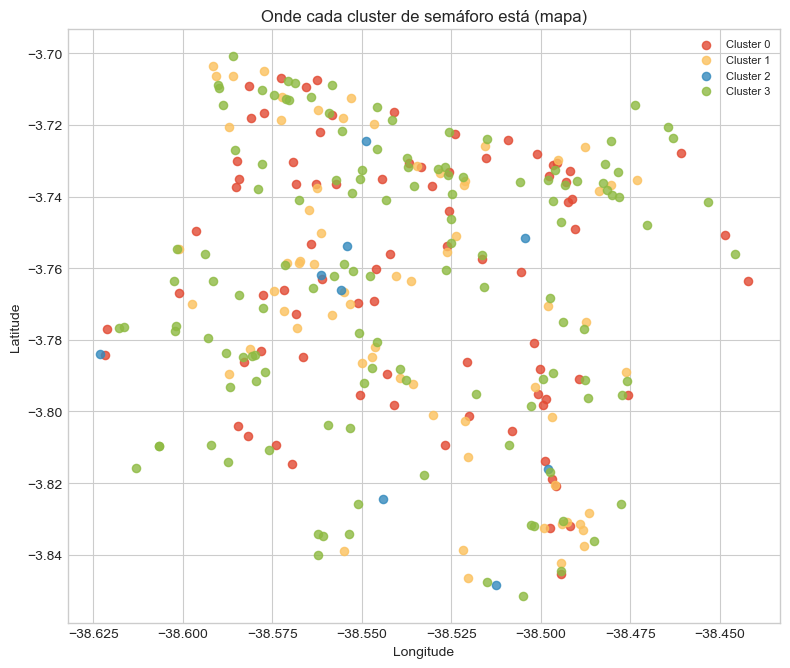

PERFIL DE CADA CLUSTER DE SEMÁFORO (k=4)
Tamanho de cada cluster:
cluster
0     80
1     67
2      9
3    126
Name: count, dtype: int64

------------------------------------------------------------------------------
CLUSTER 0  (80 semáforos, 28.4% do total)
------------------------------------------------------------------------------
Médias:
acidentes_antes        7.31
acidentes_depois       5.44
diferenca_absoluta    -1.88
variacao_pct         -15.11
delta_mortos          -0.02
delta_feridos         -2.14
delta_gravidade       -0.04

% de semáforos que mudaram o período de pico: 0%
% de semáforos que mudaram o tipo de acidente mais comum: 44%

Exemplos de cruzamentos nesse cluster:
                                 cruzamento       bairro  variacao_pct  delta_gravidade
AV. SEN. VIRGÍLIO TÁVORA & R. MARCOS MACÊDO      ALDEOTA    200.000000         0.444444
         AV. FREI CIRILO & R. ALVES RIBEIRO    MESSEJANA    -21.428571        -0.314935
             R. DOM LINO & R. AZEVEDO BOLÃO

In [11]:
"""
Clusterização dos SEMÁFOROS conforme o que mudou antes x depois da instalação

Diferença em relação ao clustering_acidentes.py: ali cada PONTO era um
acidente. Aqui cada PONTO é um SEMÁFORO, e as variáveis usadas descrevem
a MUDANÇA que aconteceu no entorno dele (queda/aumento de acidentes,
mudança na gravidade, mudança no perfil dos acidentes) — pra ver se
existem "tipos" de semáforo conforme o impacto que causaram.

Reaproveita a mesma lógica de antes/depois do impacto_semaforos.py
(quadrado de influência + janela de tempo simétrica).
"""

import json
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box, shape
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ================================================================
# >>> COLOQUE AQUI OS CAMINHOS DOS SEUS ARQUIVOS <<<
# ================================================================
CAMINHO_SEMAFOROS = r"C:\Users\Pichau\Desktop\artigo\dadosabertos_semaforosctafor.geojson"
CAMINHO_SINISTROS = r"C:\Users\Pichau\Desktop\artigo\sinistros-2015-2024.geojson"

# ================================================================
# >>> PARÂMETROS DA COMPARAÇÃO ANTES/DEPOIS (iguais ao impacto_semaforos.py) <<<
# ================================================================
JANELA_ANOS = 2
LADO_QUADRADO_M = 150
DATA_MIN_DADOS = datetime(2015, 1, 1)
DATA_MAX_DADOS = datetime(2024, 12, 31)
CRS_METRICO = "EPSG:31984"
CRS_GEOGRAFICO = "EPSG:4674"

# ================================================================
# >>> PARÂMETROS DA CLUSTERIZAÇÃO <<<
# ================================================================
K_CLUSTERS = 4
K_MAX_TESTAR = 10
RANDOM_STATE = 42


# ---------------------------------------------------------------
# Funções auxiliares
# ---------------------------------------------------------------
def classifica_periodo_dia(hora) -> str:
    if not hora or not isinstance(hora, str):
        return "não informado"
    try:
        h = int(hora.split(":")[0])
    except (ValueError, IndexError):
        return "não informado"
    if 0 <= h < 6:
        return "madrugada"
    elif 6 <= h < 12:
        return "manhã"
    elif 12 <= h < 18:
        return "tarde"
    elif 18 <= h < 24:
        return "noite"
    return "não informado"


def categoria_pico(subset: pd.DataFrame, campo: str) -> str:
    """Categoria mais frequente de `campo` nesse subconjunto (ou 'sem acidentes')."""
    if subset.empty:
        return "sem acidentes"
    return subset[campo].value_counts().idxmax()


# ---------------------------------------------------------------
# 1) Carrega semáforos e filtra os que têm janela completa de dados
# ---------------------------------------------------------------
def carrega_semaforos(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    registros = []
    for ft in raw["features"]:
        props = ft["properties"]
        data_str = props.get("DATA_IMPLANTAÇÃO")
        if not data_str:
            continue
        try:
            data_instalacao = datetime.strptime(data_str, "%d/%m/%Y")
        except ValueError:
            continue

        inicio_antes = data_instalacao - timedelta(days=365 * JANELA_ANOS)
        fim_depois = data_instalacao + timedelta(days=365 * JANELA_ANOS)
        if inicio_antes < DATA_MIN_DADOS or fim_depois > DATA_MAX_DADOS:
            continue

        registros.append({
            "codigo": props.get("CÓDIGO"),
            "cruzamento": props.get("CRUZAMENTO"),
            "bairro": props.get("BAIRRO"),
            "data_instalacao": data_instalacao,
            "inicio_antes": inicio_antes,
            "fim_depois": fim_depois,
            "geometry": shape(ft["geometry"]),
        })

    if not registros:
        raise ValueError("Nenhum semáforo com janela completa de dados encontrado.")

    gdf = gpd.GeoDataFrame(registros, geometry="geometry", crs=CRS_GEOGRAFICO)
    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 2) Carrega acidentes
# ---------------------------------------------------------------
def carrega_acidentes(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["data"] = pd.to_datetime(
        dict(year=gdf["ANO"], month=gdf["MES"], day=gdf["DIA"]), errors="coerce"
    )
    gdf = gdf.dropna(subset=["data"])
    gdf["periodo_dia"] = gdf["HORA"].apply(classifica_periodo_dia)
    gdf["NATUREZA"] = gdf["NATUREZA"].fillna("não informado").astype(str).str.strip().str.upper()
    return gdf.to_crs(CRS_METRICO)


def monta_quadrados(semaforos_gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    meia_lado = LADO_QUADRADO_M / 2
    quadrados = semaforos_gdf.copy()
    quadrados["geometry"] = quadrados.geometry.apply(
        lambda p: box(p.x - meia_lado, p.y - meia_lado, p.x + meia_lado, p.y + meia_lado)
    )
    return quadrados


# ---------------------------------------------------------------
# 3) Calcula, PRA CADA SEMÁFORO, as variáveis que descrevem a MUDANÇA
#    antes -> depois
# ---------------------------------------------------------------
def calcula_mudancas(semaforos_gdf, quadrados_gdf, acidentes_gdf) -> pd.DataFrame:
    juncao = gpd.sjoin(acidentes_gdf, quadrados_gdf, how="inner", predicate="within")

    linhas = []
    for idx, sem in semaforos_gdf.iterrows():
        dentro = juncao[juncao["index_right"] == idx]
        antes = dentro[(dentro["data"] >= sem["inicio_antes"]) & (dentro["data"] < sem["data_instalacao"])]
        depois = dentro[(dentro["data"] >= sem["data_instalacao"]) & (dentro["data"] < sem["fim_depois"])]

        n_antes, n_depois = len(antes), len(depois)
        mortos_antes, mortos_depois = int(antes["MORTOS"].sum()), int(depois["MORTOS"].sum())
        feridos_antes, feridos_depois = int(antes["FERIDOS"].sum()), int(depois["FERIDOS"].sum())

        variacao_pct = (n_depois - n_antes) / n_antes * 100 if n_antes > 0 else np.nan
        # taxa de gravidade (mortos+feridos por acidente) — evita NaN mesmo se n=0
        gravidade_antes = (mortos_antes + feridos_antes) / n_antes if n_antes > 0 else 0.0
        gravidade_depois = (mortos_depois + feridos_depois) / n_depois if n_depois > 0 else 0.0

        periodo_pico_antes = categoria_pico(antes, "periodo_dia")
        periodo_pico_depois = categoria_pico(depois, "periodo_dia")
        natureza_pico_antes = categoria_pico(antes, "NATUREZA")
        natureza_pico_depois = categoria_pico(depois, "NATUREZA")

        mudou_periodo = (
            periodo_pico_antes != periodo_pico_depois
            and "sem acidentes" not in (periodo_pico_antes, periodo_pico_depois)
        )
        mudou_natureza = (
            natureza_pico_antes != natureza_pico_depois
            and "sem acidentes" not in (natureza_pico_antes, natureza_pico_depois)
        )

        linhas.append({
            "codigo": sem["codigo"],
            "cruzamento": sem["cruzamento"],
            "bairro": sem["bairro"],
            "data_instalacao": sem["data_instalacao"].date(),
            "acidentes_antes": n_antes,
            "acidentes_depois": n_depois,
            "diferenca_absoluta": n_depois - n_antes,
            "variacao_pct": variacao_pct,
            "mortos_antes": mortos_antes,
            "mortos_depois": mortos_depois,
            "delta_mortos": mortos_depois - mortos_antes,
            "feridos_antes": feridos_antes,
            "feridos_depois": feridos_depois,
            "delta_feridos": feridos_depois - feridos_antes,
            "gravidade_antes": gravidade_antes,
            "gravidade_depois": gravidade_depois,
            "delta_gravidade": gravidade_depois - gravidade_antes,
            "periodo_pico_antes": periodo_pico_antes,
            "periodo_pico_depois": periodo_pico_depois,
            "mudou_periodo_pico": mudou_periodo,
            "natureza_pico_antes": natureza_pico_antes,
            "natureza_pico_depois": natureza_pico_depois,
            "mudou_natureza_pico": mudou_natureza,
        })

    return pd.DataFrame(linhas)


# ---------------------------------------------------------------
# 4) Monta a matriz de atributos pra clusterizar (só as variáveis de MUDANÇA)
# ---------------------------------------------------------------
def monta_matriz_mudanca(resultado: pd.DataFrame):
    # variação percentual não dá pra usar direto (tem NaN quando antes=0);
    # usamos ela só quando existe, e criamos uma versão "segura" pra quando não existe
    df = resultado.copy()
    df["variacao_pct_segura"] = df["variacao_pct"].fillna(
        np.sign(df["diferenca_absoluta"]) * 200  # trata "sem antes" como variação extrema
    )
    df["mudou_periodo_pico"] = df["mudou_periodo_pico"].astype(int)
    df["mudou_natureza_pico"] = df["mudou_natureza_pico"].astype(int)

    numericos = df[[
        "diferenca_absoluta", "variacao_pct_segura",
        "delta_mortos", "delta_feridos", "delta_gravidade",
        "mudou_periodo_pico", "mudou_natureza_pico",
    ]]
    return numericos, df


# ---------------------------------------------------------------
# Execução
# ---------------------------------------------------------------
semaforos_gdf = carrega_semaforos(CAMINHO_SEMAFOROS)
acidentes_gdf = carrega_acidentes(CAMINHO_SINISTROS)
quadrados_gdf = monta_quadrados(semaforos_gdf)

resultado = calcula_mudancas(semaforos_gdf, quadrados_gdf, acidentes_gdf)

# guarda lat/long (em CRS geográfico) de cada semáforo, pra poder plotar no mapa depois
coords_geograficas = semaforos_gdf.to_crs(CRS_GEOGRAFICO)
resultado["longitude"] = coords_geograficas.geometry.x.values
resultado["latitude"] = coords_geograficas.geometry.y.values

matriz, resultado = monta_matriz_mudanca(resultado)
scaler = StandardScaler()
matriz_padronizada = scaler.fit_transform(matriz)

# ---------------------------------------------------------------
# Método do cotovelo
# ---------------------------------------------------------------
inercias = []
ks_testados = range(1, K_MAX_TESTAR + 1)
for k in ks_testados:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    modelo.fit(matriz_padronizada)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(ks_testados), inercias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — mudança antes/depois dos semáforos")
plt.xticks(list(ks_testados))
plt.tight_layout()
plt.savefig("semaforos_metodo_cotovelo.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# K-Means final
# ---------------------------------------------------------------
kmeans = KMeans(n_clusters=K_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
resultado["cluster"] = kmeans.fit_predict(matriz_padronizada)

# ---------------------------------------------------------------
# Visualização 1: PCA genérico (mesmo estilo dos gráficos anteriores)
# ---------------------------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
componentes = pca.fit_transform(matriz_padronizada)
resultado["pca_1"] = componentes[:, 0]
resultado["pca_2"] = componentes[:, 1]
variancia_explicada = pca.explained_variance_ratio_.sum() * 100

CORES = ["#E24A33", "#FBC15E", "#348ABD", "#8EBA42", "#988ED5", "#FFB5B8"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.set_facecolor("#EAEAF2")
    ax.grid(color="white", linewidth=1.2)
    ax.set_axisbelow(True)

ax1.scatter(resultado["pca_1"], resultado["pca_2"], color="#3B7DD8", s=25, alpha=0.7)
ax1.set_title("Semáforos sem rótulo (projeção PCA)")
ax1.set_xlabel("Componente 1")
ax1.set_ylabel("Componente 2")

for i in range(K_CLUSTERS):
    grupo = resultado[resultado["cluster"] == i]
    ax2.scatter(grupo["pca_1"], grupo["pca_2"], color=CORES[i % len(CORES)], s=25, alpha=0.7, label=f"Cluster {i}")
ax2.set_title(f"Semáforos agrupados pela MUDANÇA (K-Means, k={K_CLUSTERS})")
ax2.set_xlabel("Componente 1")
ax2.legend(fontsize=8)

fig.suptitle(f"Clusterização por impacto do semáforo — PCA explica {variancia_explicada:.0f}% da variância", y=1.02)
fig.tight_layout()
plt.savefig("semaforos_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------
# Visualização 2: gráfico de negócio (variação % x delta gravidade),
# muito mais interpretável que o PCA
# ---------------------------------------------------------------
plt.figure(figsize=(8, 6))
for i in range(K_CLUSTERS):
    grupo = resultado[resultado["cluster"] == i]
    plt.scatter(grupo["variacao_pct_segura"], grupo["delta_gravidade"],
                color=CORES[i % len(CORES)], s=30, alpha=0.75, label=f"Cluster {i}")
plt.axhline(0, color="grey", linewidth=0.8)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Variação % no nº de acidentes (negativo = melhorou)")
plt.ylabel("Variação na gravidade (mortos+feridos por acidente)")
plt.title("Cada semáforo: quanto mudou o Nº de acidentes x quanto mudou a gravidade")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("semaforos_clusters_variacao_gravidade.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Visualização 3: mapa (lat/long) colorido por cluster
# ---------------------------------------------------------------
plt.figure(figsize=(8, 8))
for i in range(K_CLUSTERS):
    grupo = resultado[resultado["cluster"] == i]
    plt.scatter(grupo["longitude"], grupo["latitude"], color=CORES[i % len(CORES)],
                s=35, alpha=0.8, label=f"Cluster {i}")
plt.title("Onde cada cluster de semáforo está (mapa)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(fontsize=8)
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.savefig("semaforos_clusters_mapa.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Perfil de cada cluster
# ---------------------------------------------------------------
print("=" * 78)
print(f"PERFIL DE CADA CLUSTER DE SEMÁFORO (k={K_CLUSTERS})")
print("=" * 78)
print(f"Tamanho de cada cluster:\n{resultado['cluster'].value_counts().sort_index()}\n")

campos_numericos_perfil = ["acidentes_antes", "acidentes_depois", "diferenca_absoluta",
                           "variacao_pct", "delta_mortos", "delta_feridos", "delta_gravidade"]

for i in range(K_CLUSTERS):
    grupo = resultado[resultado["cluster"] == i]
    print("-" * 78)
    print(f"CLUSTER {i}  ({len(grupo)} semáforos, {len(grupo)/len(resultado)*100:.1f}% do total)")
    print("-" * 78)
    print("Médias:")
    print(grupo[campos_numericos_perfil].mean().round(2).to_string())
    print(f"\n% de semáforos que mudaram o período de pico: {grupo['mudou_periodo_pico'].mean()*100:.0f}%")
    print(f"% de semáforos que mudaram o tipo de acidente mais comum: {grupo['mudou_natureza_pico'].mean()*100:.0f}%")
    print("\nExemplos de cruzamentos nesse cluster:")
    print(grupo[["cruzamento", "bairro", "variacao_pct", "delta_gravidade"]].head(5).to_string(index=False))
    print()

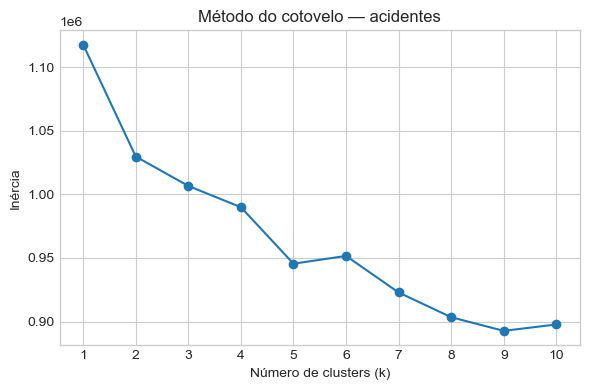

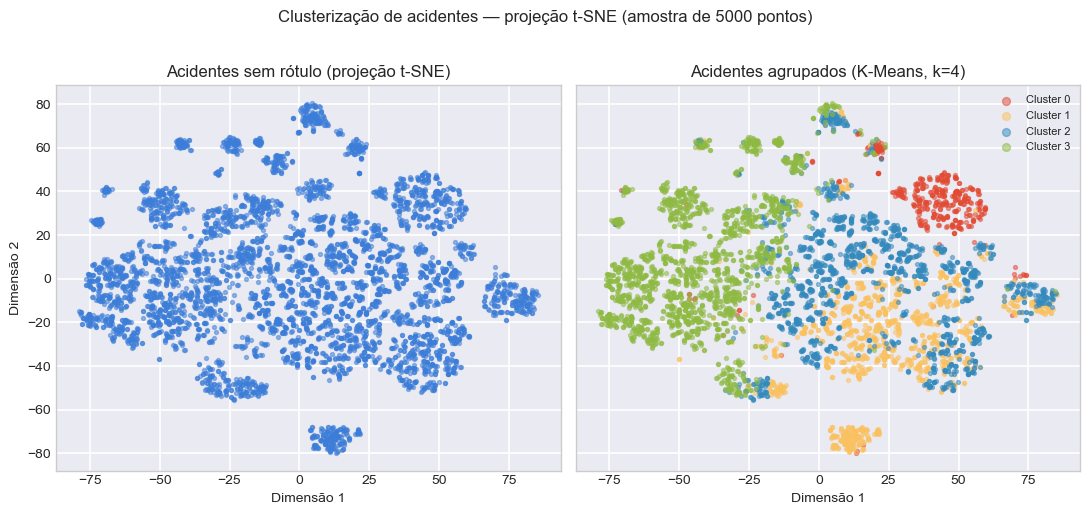

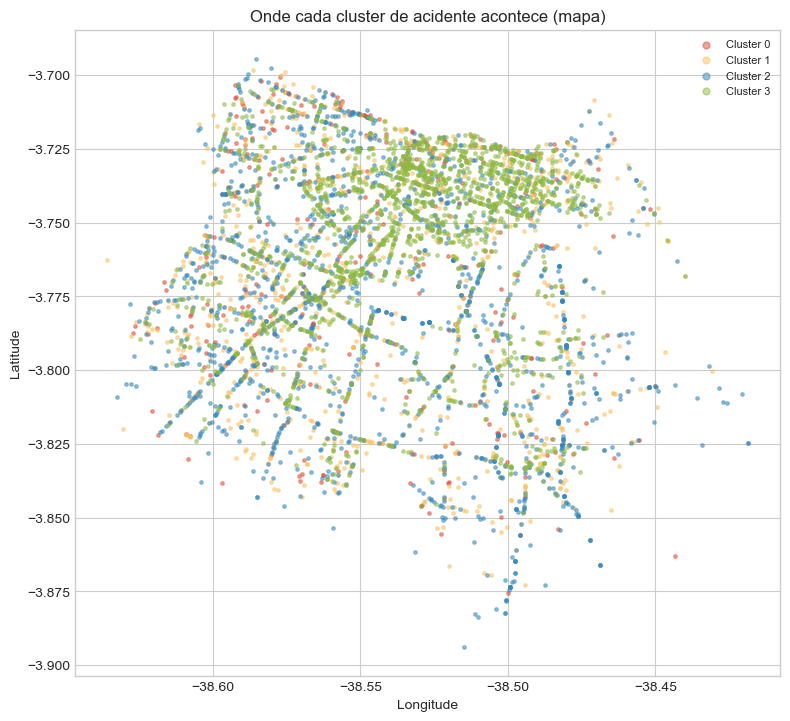

PERFIL DE CADA CLUSTER (k=4)
Tamanho de cada cluster:
cluster
0    10542
1    29631
2    42677
3    47973
Name: count, dtype: int64

------------------------------------------------------------------------------
CLUSTER 0  (10542 acidentes, 8.1% do total)
------------------------------------------------------------------------------
Médias numéricas:
MORTOS               0.11
FERIDOS              1.18
ILESOS               0.18
AUTOMOVEL            0.39
MOTOCICLETA          0.42
BICICLETA            0.02
CAMINHAO             0.02
dist_semaforo_m    255.06

Categoria mais comum em cada campo:
  NATUREZA: ATROPELAMENTO (96% do cluster)
  periodo_dia: tarde (38% do cluster)
  dia_semana: Saturday (17% do cluster)
  CONTROLETRAFEGO: NÃO INFORMADO (88% do cluster)
  TIPOCRUZAMENTO: MEIO DE QUADRA (79% do cluster)
  modo_controle_proximo: LOCAL (35% do cluster)

------------------------------------------------------------------------------
CLUSTER 1  (29631 acidentes, 22.6% do total)
--------

In [12]:
"""
Clusterização dos acidentes de trânsito - Fortaleza

Agrupa os acidentes (K-Means) usando variáveis combinadas de dois arquivos:

  - sinistros-2015-2024.geojson: severidade (mortos/feridos/ilesos), tipos de
    veículo envolvidos, natureza do acidente, tipo de cruzamento, controle de
    tráfego no local, horário/dia da semana/mês.

  - dadosabertos_semaforosctafor.geojson: usado pra calcular a distância de
    cada acidente até o semáforo mais próximo, e trazer características
    desse semáforo (modo de controle, se tem botão de pedestre, etc.)

A ideia é ver se emergem "perfis" de acidente (ex.: acidentes noturnos de
moto com alta gravidade longe de semáforo x colisões leves de carro de dia
perto de semáforo centralizado etc.) — tanto num gráfico 2D (via t-SNE) quanto
num mapa (lat/long) colorido por cluster.
"""

import json
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# ================================================================
# >>> COLOQUE AQUI OS CAMINHOS DOS SEUS ARQUIVOS <<<
# ================================================================
CAMINHO_SINISTROS = r"C:\Users\Pichau\Desktop\artigo\sinistros-2015-2024.geojson"
CAMINHO_SEMAFOROS = r"C:\Users\Pichau\Desktop\artigo\dadosabertos_semaforosctafor.geojson"

# ================================================================
# >>> PARÂMETROS <<<
# ================================================================
K_CLUSTERS = 4                  # número de grupos (ajuste depois de olhar o cotovelo)
K_MAX_TESTAR = 10               # até quantos clusters testar no método do cotovelo
DISTANCIA_MAX_SEMAFORO_M = 300  # além disso, considera "sem semáforo próximo"
AMOSTRA_PARA_GRAFICO = 5000     # nº de pontos plotados (t-SNE é pesado, evite passar de ~8-10 mil)
RANDOM_STATE = 42

CRS_METRICO = "EPSG:31984"      # SIRGAS 2000 / UTM 24S (Fortaleza/CE)
CRS_GEOGRAFICO = "EPSG:4674"


# ---------------------------------------------------------------
# Funções auxiliares
# ---------------------------------------------------------------
def classifica_periodo_dia(hora) -> str:
    if not hora or not isinstance(hora, str):
        return "não informado"
    try:
        h = int(hora.split(":")[0])
    except (ValueError, IndexError):
        return "não informado"
    if 0 <= h < 6:
        return "madrugada"
    elif 6 <= h < 12:
        return "manhã"
    elif 12 <= h < 18:
        return "tarde"
    elif 18 <= h < 24:
        return "noite"
    return "não informado"


def normaliza_texto(serie: pd.Series) -> pd.Series:
    return serie.fillna("não informado").astype(str).str.strip().str.upper()


def agrupa_raras(serie: pd.Series, top_n: int) -> pd.Series:
    """Mantém só as top_n categorias mais frequentes; o resto vira 'OUTROS'."""
    mais_frequentes = serie.value_counts().head(top_n).index
    return serie.where(serie.isin(mais_frequentes), "OUTROS")


# ---------------------------------------------------------------
# 1) Carrega acidentes + engenharia de atributos de tempo
# ---------------------------------------------------------------
def carrega_acidentes(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)

    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["data"] = pd.to_datetime(
        dict(year=gdf["ANO"], month=gdf["MES"], day=gdf["DIA"]), errors="coerce"
    )
    gdf = gdf.dropna(subset=["data"]).reset_index(drop=True)

    gdf["periodo_dia"] = gdf["HORA"].apply(classifica_periodo_dia)
    gdf["dia_semana"] = gdf["data"].dt.day_name()
    gdf["mes"] = gdf["data"].dt.month

    for campo in ["NATUREZA", "TIPOCRUZAMENTO", "CONTROLETRAFEGO", "USOSOLO", "SEVERIDADE"]:
        gdf[campo] = normaliza_texto(gdf[campo])

    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 2) Carrega semáforos (todos com coordenada válida)
# ---------------------------------------------------------------
def carrega_semaforos(caminho: str) -> gpd.GeoDataFrame:
    with open(caminho, encoding="utf-8") as f:
        raw = json.load(f)
    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs=CRS_GEOGRAFICO)
    gdf["MODO_CONTROLE"] = normaliza_texto(gdf["MODO_CONTROLE"])
    return gdf.to_crs(CRS_METRICO)


# ---------------------------------------------------------------
# 3) Pra cada acidente, acha o semáforo mais próximo (KDTree)
# ---------------------------------------------------------------
def anexa_semaforo_mais_proximo(acidentes_gdf, semaforos_gdf) -> pd.DataFrame:
    coords_acidentes = np.column_stack([acidentes_gdf.geometry.x, acidentes_gdf.geometry.y])
    coords_semaforos = np.column_stack([semaforos_gdf.geometry.x, semaforos_gdf.geometry.y])

    arvore = cKDTree(coords_semaforos)
    distancias, indices = arvore.query(coords_acidentes, k=1)

    modo_controle_proximo = semaforos_gdf["MODO_CONTROLE"].values[indices]
    modo_controle_proximo = np.where(
        distancias <= DISTANCIA_MAX_SEMAFORO_M, modo_controle_proximo, "SEM SEMÁFORO PRÓXIMO"
    )

    resultado = acidentes_gdf.copy()
    resultado["dist_semaforo_m"] = distancias
    resultado["perto_de_semaforo"] = distancias <= DISTANCIA_MAX_SEMAFORO_M
    resultado["modo_controle_proximo"] = modo_controle_proximo
    return resultado


# ---------------------------------------------------------------
# 4) Monta a matriz de atributos (numéricos + categóricos em dummies)
# ---------------------------------------------------------------
def monta_matriz_atributos(df: pd.DataFrame):
    numericos = df[[
        "MORTOS", "FERIDOS", "ILESOS",
        "AUTOMOVEL", "ONIBUS", "BICICLETA", "CAMINHAO", "MICROONIBUS",
        "CICLOMOTOR", "MOTOCICLETA", "TRACAOANIMAL", "TREM",
        "dist_semaforo_m", "mes",
    ]].fillna(0)

    categoricos_config = {
        "NATUREZA": 8,
        "TIPOCRUZAMENTO": 6,
        "CONTROLETRAFEGO": 6,
        "USOSOLO": 3,
        "periodo_dia": 5,
        "dia_semana": 7,
        "modo_controle_proximo": 6,
    }
    blocos_categoricos = []
    for campo, top_n in categoricos_config.items():
        agrupado = agrupa_raras(df[campo], top_n)
        dummies = pd.get_dummies(agrupado, prefix=campo)
        blocos_categoricos.append(dummies)

    matriz = pd.concat([numericos.reset_index(drop=True)] + [b.reset_index(drop=True) for b in blocos_categoricos], axis=1)
    return matriz


# ---------------------------------------------------------------
# Execução
# ---------------------------------------------------------------
acidentes_gdf = carrega_acidentes(CAMINHO_SINISTROS)
semaforos_gdf = carrega_semaforos(CAMINHO_SEMAFOROS)
acidentes_gdf = anexa_semaforo_mais_proximo(acidentes_gdf, semaforos_gdf)

matriz = monta_matriz_atributos(acidentes_gdf)
scaler = StandardScaler()
matriz_padronizada = scaler.fit_transform(matriz)

# ---------------------------------------------------------------
# Método do cotovelo (numa amostra, só pra não demorar demais)
# ---------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
idx_amostra_cotovelo = rng.choice(len(matriz_padronizada), size=min(20000, len(matriz_padronizada)), replace=False)

inercias = []
ks_testados = range(1, K_MAX_TESTAR + 1)
for k in ks_testados:
    modelo = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, batch_size=1024)
    modelo.fit(matriz_padronizada[idx_amostra_cotovelo])
    inercias.append(modelo.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(ks_testados), inercias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — acidentes")
plt.xticks(list(ks_testados))
plt.tight_layout()
plt.savefig("acidentes_metodo_cotovelo.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# K-Means final (nos dados todos)
# ---------------------------------------------------------------
kmeans = MiniBatchKMeans(n_clusters=K_CLUSTERS, random_state=RANDOM_STATE, n_init=10, batch_size=2048)
clusters = kmeans.fit_predict(matriz_padronizada)
acidentes_gdf["cluster"] = clusters

# ---------------------------------------------------------------
# t-SNE só pra poder visualizar em 2D
# (t-SNE é bem mais pesado que PCA — O(n²) — então roda só numa AMOSTRA,
#  não na base inteira. O KMeans em cima já foi calculado com todos os dados;
#  o t-SNE é só pra desenhar o gráfico.)
# ---------------------------------------------------------------
idx_plot = rng.choice(len(acidentes_gdf), size=min(AMOSTRA_PARA_GRAFICO, len(acidentes_gdf)), replace=False)
amostra = acidentes_gdf.iloc[idx_plot].copy()
matriz_amostra = matriz_padronizada[idx_plot]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
componentes = tsne.fit_transform(matriz_amostra)
amostra["tsne_1"] = componentes[:, 0]
amostra["tsne_2"] = componentes[:, 1]

CORES = ["#E24A33", "#FBC15E", "#348ABD", "#8EBA42", "#988ED5", "#FFB5B8", "#777777"]

# ---- painel 1: t-SNE sem rótulo x t-SNE colorido por cluster ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.set_facecolor("#EAEAF2")
    ax.grid(color="white", linewidth=1.2)
    ax.set_axisbelow(True)

ax1.scatter(amostra["tsne_1"], amostra["tsne_2"], color="#3B7DD8", s=8, alpha=0.5)
ax1.set_title("Acidentes sem rótulo (projeção t-SNE)")
ax1.set_xlabel("Dimensão 1")
ax1.set_ylabel("Dimensão 2")

for i in range(K_CLUSTERS):
    grupo = amostra[amostra["cluster"] == i]
    ax2.scatter(grupo["tsne_1"], grupo["tsne_2"], color=CORES[i % len(CORES)], s=8, alpha=0.5, label=f"Cluster {i}")
ax2.set_title(f"Acidentes agrupados (K-Means, k={K_CLUSTERS})")
ax2.set_xlabel("Dimensão 1")
ax2.legend(markerscale=2, fontsize=8)

fig.suptitle(f"Clusterização de acidentes — projeção t-SNE (amostra de {len(amostra)} pontos)", y=1.02)
fig.tight_layout()
plt.savefig("acidentes_clusters_tsne.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- painel 2: mapa (lat/long) colorido por cluster ----
plt.figure(figsize=(8, 8))
for i in range(K_CLUSTERS):
    grupo = amostra[amostra["cluster"] == i]
    plt.scatter(grupo["LONGITUDE"], grupo["LATITUDE"], color=CORES[i % len(CORES)], s=6, alpha=0.5, label=f"Cluster {i}")
plt.title("Onde cada cluster de acidente acontece (mapa)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=2, fontsize=8)
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.savefig("acidentes_clusters_mapa.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Perfil de cada cluster — o que caracteriza cada grupo
# ---------------------------------------------------------------
print("=" * 78)
print(f"PERFIL DE CADA CLUSTER (k={K_CLUSTERS})")
print("=" * 78)
print(f"Tamanho de cada cluster:\n{acidentes_gdf['cluster'].value_counts().sort_index()}\n")

campos_numericos_perfil = ["MORTOS", "FERIDOS", "ILESOS", "AUTOMOVEL", "MOTOCICLETA",
                           "BICICLETA", "CAMINHAO", "dist_semaforo_m"]
campos_categoricos_perfil = ["NATUREZA", "periodo_dia", "dia_semana", "CONTROLETRAFEGO",
                             "TIPOCRUZAMENTO", "modo_controle_proximo"]

for i in range(K_CLUSTERS):
    grupo = acidentes_gdf[acidentes_gdf["cluster"] == i]
    print("-" * 78)
    print(f"CLUSTER {i}  ({len(grupo)} acidentes, {len(grupo)/len(acidentes_gdf)*100:.1f}% do total)")
    print("-" * 78)
    print("Médias numéricas:")
    print(grupo[campos_numericos_perfil].mean().round(2).to_string())
    print("\nCategoria mais comum em cada campo:")
    for campo in campos_categoricos_perfil:
        moda = grupo[campo].mode()
        if not moda.empty:
            pct = (grupo[campo] == moda.iloc[0]).mean() * 100
            print(f"  {campo}: {moda.iloc[0]} ({pct:.0f}% do cluster)")
    print()